# 보드게임 추천 시스템 (Team 4): Colab 단계별 실행판

BoardGameGeek 평점으로 사용자가 좋아할 보드게임 10개를 추천하고 방법별 성능을 비교한다.
기존 `main_fast.py` + `main_hybrid.py` 를 **기능 하나당 셀 하나**로 나누고,
단계마다 **중간 결과를 눈으로 확인하는 셀(🔍)** 을 넣었다. 기획서의 선택 항목 3개(🆕)도 추가했다.

| 장 | 내용 |
|---|---|
| 0 | 준비: 설치, 경로, zip 에서 CSV 꺼내기 |
| 1 | 전처리: 원본 정리 → 사용자 8:2 분할 → 게임 1,000개 선정 → 사용자 샘플링 |
| 2 | EDA: 샘플링 전후 비교 |
| 3 | 평가 틀: 입력 80% / 정답 20%, NDCG·Precision·Recall, 인기 순 기준선 |
| 4 | kNN: 유사도 → 이웃 → 예상 평점 → 추천 |
| 5 | Apriori 연관 규칙: 규칙 찾기 → 규칙으로 추천 |
| 6 | 하이브리드: kNN + 연관 규칙 점수 가중 평균 |
| 7 | 🆕 행렬 분해: SGD + L2 학습 → 새 사용자 요인 추정 → 추천 |
| 8 | 실험 공통 도구 |
| 9 | 파라미터 선택: kNN·연관 규칙 |
| 10 | 🆕 선호 기준 7·8·9점 비교 |
| 11 | 하이브리드 가중치 선택 |
| 12 | 🆕 행렬 분해 파라미터 선택 |
| 13 | 최종 테스트 |
| 14 | 🆕 부트스트랩 95% 신뢰구간 |
| 15 | 추천 시스템 직접 사용 |

**셀 표시**: `▶` = 실행해서 결과를 만드는 셀, `🔍` = 중간 결과를 확인하는 셀, 표시 없음 = 함수 정의.

## 실행 전 준비
1. Colab 왼쪽 **📁 파일 탭 → 업로드**로 데이터 zip 2개(`훈련용Geek데이테섯.zip`, `테스트용.zip`)를 `/content` 에 올린다.
   zip 이름은 달라도 된다. zip 안의 파일 이름(`bgg-15m-reviews.csv`, `user_ratings.csv`, `games.csv`)으로 찾는다.
   zip 대신 이 CSV 3개를 직접 올려도 된다.
2. 위에서부터 한 셀씩 실행한다(Shift+Enter). 한 번에 돌리려면 **런타임 → 모두 실행**.
3. 결과(표·그래프·선택된 설정)는 `/content/boardgame_rec/outputs/` 에 저장된다. 오래 걸리는 파라미터 선택 셀(9·10·11·12장)은
   같은 런타임 안에서는 저장된 결과를 재사용하고, 다시 계산하려면 그 셀의 `FORCE = True` 로 바꾼다.
4. **런타임이 끊기면 올린 파일과 결과가 모두 지워진다.** 1장 끝(1-14)과 14장 끝(14-5)에서 만드는 `boardgame_rec_backup.zip` 을
   파일 탭에서 오른쪽 클릭 → 다운로드해 두면, 새 세션에서는 원본 zip 대신 **이 백업 zip 하나만 올리고** 0장부터 실행하면 된다.
   0-5 셀이 백업을 자동으로 풀고, 1-3 의 오래 걸리는 원본 정리를 건너뛴다.

오래 걸리는 셀은 **진행 막대**로 얼마나 진행됐는지 보여 준다. 쓸모없는 경고 출력은 0-0 셀에서 막는다.

## 0. 준비

In [1]:
# 0-0. ▶ 불필요한 경고 출력 막기 (가장 먼저 실행)
# Colab(Python 3.13)은 셀이 출력할 때마다 DeprecationWarning 을 찍어 화면이 수천 줄로 길어지고 브라우저가 느려진다. 결과와는 무관하다.
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
try:                                                       # 경고의 원인 함수 자체를 경고 없는 것으로 바꿔 둔다
    import datetime as _dt
    import jupyter_client.session as _jcs
    _jcs.utcnow = lambda: _dt.datetime.now(_dt.timezone.utc)
except Exception:
    pass

In [2]:
# 0-1. ▶ 패키지·한글 폰트 설치 (Colab 에는 pandas·numpy·scipy·scikit-learn·numba·tqdm 이 이미 있다)
!pip -q install "mlxtend>=0.23.4" > /dev/null
!apt-get -qq install -y fonts-nanum > /dev/null
print("설치 완료")

설치 완료


In [3]:
# 0-2. ▶ 라이브러리 불러오기
import gc
import itertools
import json
import shutil
import time
import zipfile
from pathlib import Path

import matplotlib.font_manager as fm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from IPython.display import Image, Markdown, display
from mlxtend.frequent_patterns import apriori, association_rules
from numba import njit
from sklearn.metrics.pairwise import cosine_similarity
from tqdm.auto import tqdm                                 # 진행 막대

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

In [4]:
# 0-3. ▶ 경로·샘플 크기·그래프 설정 (Colab 왼쪽 📁 파일 탭에 직접 올린 파일 사용)
# 주의: /content 는 런타임이 끊기면 올린 파일·결과가 모두 지워진다. 결과가 필요하면 끝난 뒤 boardgame_rec/outputs 를 내려받는다.
UPLOAD_DIR = Path("/content") if Path("/content").exists() else Path.cwd()   # 올린 파일 위치 (로컬 실행이면 현재 폴더)
ZIP_DIR = UPLOAD_DIR                                       # 여기서 zip 을 찾는다
ROOT = UPLOAD_DIR / "boardgame_rec"                        # 정리된 데이터·표·그래프 저장
# zip 대신 CSV 를 풀어서 올렸으면 그 자리를 원본 폴더로 쓴다
RAW = UPLOAD_DIR if (UPLOAD_DIR / "bgg-15m-reviews.csv").exists() else ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"
RES = ROOT / "outputs" / "results"
FIG = ROOT / "outputs" / "figures"
for d in (RAW, PROC, RES, FIG):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
SAMPLE = dict(n_train=10_000, n_val=2_000, n_test=3_000)   # 학습·검증·테스트 사용자 수 (기획서 2.1)

# 한글 폰트: Colab 은 나눔고딕(0-1 에서 설치), Windows 는 맑은 고딕
NANUM = Path("/usr/share/fonts/truetype/nanum/NanumGothic.ttf")
if NANUM.exists():
    fm.fontManager.addfont(str(NANUM))
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a5cd1"]  # 색각 이상자도 구분되는 색, 순서 고정
plt.rcParams.update({"font.family": "NanumGothic" if NANUM.exists() else "Malgun Gothic",
                     "axes.unicode_minus": False,      # 한글 폰트에서 음수 기호 깨짐 방지
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e4e3df", "axes.axisbelow": True,
                     "legend.frameon": False})
print("올린 파일 위치:", UPLOAD_DIR)
print("  zip:", [p.name for p in ZIP_DIR.glob("*.zip")] or "없음")
print("  csv:", [p.name for p in UPLOAD_DIR.glob("*.csv")] or "없음")
print("결과 저장 위치:", ROOT)

올린 파일 위치: /content
  zip: ['테스트용.zip', '훈련용Geek데이테섯.zip']
  csv: 없음
결과 저장 위치: /content/boardgame_rec


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [5]:
# 0-4. zip 에서 필요한 파일만 꺼내는 함수
NEEDED = {"bgg-15m-reviews.csv": "reviews_clean.parquet",   # 학습·검증
          "user_ratings.csv": "test_clean.parquet",         # 테스트
          "games.csv": None}                                # 게임 ID → 이름


BACKUP = "boardgame_rec_backup.zip"                         # 1-14·16장에서 만드는 백업


def restore_backup():
    """올려 둔 백업 zip 이 있고 아직 정리된 데이터가 없으면 풀어서 이어서 시작한다."""
    bk = UPLOAD_DIR / BACKUP
    if not bk.exists():
        return
    if not zipfile.is_zipfile(bk):
        print(f"  ⚠ {BACKUP} 는 온전한 zip 이 아닙니다. 업로드가 끝났는지 확인하세요.")
    elif (PROC / "reviews_clean.parquet").exists():
        print(f"  {BACKUP}: 이미 풀려 있음")
    else:
        with zipfile.ZipFile(bk) as zf:
            for m in tqdm(zf.infolist(), desc="백업 풀기"):
                zf.extract(m, UPLOAD_DIR)
        print(f"  {BACKUP}: 이전 세션의 정리된 데이터·결과를 복원했습니다.")


def extract_raw():
    """ZIP_DIR 의 zip 들에서 필요한 파일을 찾아 RAW 에 푼다. 정리된 parquet 가 이미 있으면 큰 파일은 건너뛴다."""
    zips = []
    for z in sorted(ZIP_DIR.glob("*.zip")):
        if z.name == BACKUP:
            continue
        if zipfile.is_zipfile(z):
            zips.append(z)
        else:                                                  # 업로드가 덜 끝난 zip 은 건너뛰고 알려 준다
            print(f"  ⚠ {z.name} ({z.stat().st_size / 2**20:,.0f}MB) 는 온전한 zip 이 아닙니다. 업로드가 끝났는지 확인하세요.")
    for fname, parquet in NEEDED.items():
        if (RAW / fname).exists() or (parquet and (PROC / parquet).exists()):
            print(f"  {fname}: 이미 있음")
            continue
        for z in zips:
            with zipfile.ZipFile(z) as zf:
                member = next((m for m in zf.namelist() if m.rsplit("/", 1)[-1] == fname), None)
                if member:
                    part = RAW / (fname + ".part")             # 중간에 끊기면 .part 만 남는다
                    size = zf.getinfo(member).file_size
                    with zf.open(member) as src, open(part, "wb") as dst, \
                            tqdm(total=size, unit="B", unit_scale=True, desc=f"{fname} 풀기") as bar:
                        while block := src.read(16 * 2**20):
                            dst.write(block)
                            bar.update(len(block))
                    part.replace(RAW / fname)
                    break
        else:
            raise FileNotFoundError(f"{fname} 이 든 zip 을 {ZIP_DIR} 에서 찾지 못했습니다. zip 을 올렸는지 확인하세요.")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [6]:
# 0-5. ▶ 백업 복원 또는 zip 풀기 (처음 한 번 몇 분)
restore_backup()
extract_raw()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


bgg-15m-reviews.csv 풀기:   0%|          | 0.00/1.39G [00:00<?, ?B/s]

user_ratings.csv 풀기:   0%|          | 0.00/399M [00:00<?, ?B/s]

games.csv 풀기:   0%|          | 0.00/22.1M [00:00<?, ?B/s]

## 1. 전처리: 원본 정리와 샘플링
원본(1.4GB)은 필요한 열(사용자·게임 ID·평점)만 나눠 읽고 parquet 으로 저장해 재사용한다.
순서: **원본 정리 → 리뷰 사용자 8:2 분할 → 학습 사용자 기준 인기 게임 1,000개 → 테스트는 새 사용자만 → 평점 50개 이상 사용자 무작위 추출**.

In [7]:
# 1-1. 원본 정리 함수
# 원본별 (파일 이름, {원래 열 이름: 통일할 열 이름})
SOURCES = {
    "reviews": ("bgg-15m-reviews.csv", {"user": "user", "ID": "game_id", "rating": "rating"}),
    "test": ("user_ratings.csv", {"Username": "user", "BGGId": "game_id", "Rating": "rating"}),
}


def load_clean(name):
    """원본 정리: 이름 공백 제거, 게임 ID 정수화, 결측·1~10 범위 밖 제거, 중복은 마지막 기록만."""
    out = PROC / f"{name}_clean.parquet"
    if out.exists():
        print(f"  {name}: 저장된 parquet 사용")
        return pd.read_parquet(out)
    file, cols = SOURCES[name]
    parts, n_raw, path = [], 0, RAW / file
    with open(path, "rb") as f, tqdm(total=path.stat().st_size, unit="B", unit_scale=True,
                                     desc=f"{name} 읽기·정리") as bar:   # 진행 = 읽은 파일 크기
        reader = pd.read_csv(f, usecols=list(cols), chunksize=2_000_000,      # 필요한 열만, 200만 행씩
                             dtype={c: ("float32" if cols[c] == "rating" else "string[pyarrow]") for c in cols})  # Arrow 문자열: 메모리 약 1/3
        for chunk in reader:
            n_raw += len(chunk)
            df = chunk.rename(columns=cols)
            df["game_id"] = pd.to_numeric(df["game_id"], errors="coerce")  # 숫자가 아니면 NaN → 제거
            df["user"] = df["user"].str.strip()
            df = df.dropna()
            df = df[(df["user"] != "") & df["rating"].between(1, 10)]
            parts.append(df.astype({"game_id": "int32"}))
            bar.update(max(0, f.tell() - bar.n))
        bar.update(bar.total - bar.n)
    t0 = time.time()
    print(f"  {name}: 중복 제거·저장 중...", end=" ", flush=True)
    df = pd.concat(parts, ignore_index=True)
    del parts
    n_clean = len(df)
    df = df.drop_duplicates(["user", "game_id"], keep="last").reset_index(drop=True)
    df["user"] = df["user"].astype(str)
    df.to_parquet(out, index=False)
    print(f"완료 ({time.time() - t0:.0f}초, {len(df):,}행)")
    pd.DataFrame([dict(file=file, raw=n_raw, after_clean=n_clean, after_dedup=len(df),        # 정리 전후 행 수 기록
                       users=df["user"].nunique(), games=df["game_id"].nunique())]
                 ).to_csv(RES / f"clean_counts_{name}.csv", index=False)
    return df


def game_names():
    """게임 ID → 이름."""
    g = pd.read_csv(RAW / "games.csv", usecols=["BGGId", "Name"])
    return g.set_index("BGGId")["Name"]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [8]:
# 1-2. 🔍 원본 파일 생김새 (앞 5줄)
for name, (file, cols) in SOURCES.items():
    print(f"[{file}] 쓰는 열: {list(cols)}")
    display(pd.read_csv(RAW / file, nrows=5) if (RAW / file).exists() else "원본이 없음 (이미 정리된 parquet 사용)")
display(pd.read_csv(RAW / "games.csv", nrows=5, usecols=["BGGId", "Name", "YearPublished"]))

[bgg-15m-reviews.csv] 쓰는 열: ['user', 'ID', 'rating']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Unnamed: 0,user,rating,comment,ID,name
0,0,Torsten,10.0,NaN,30549,Pandemic
1,1,mitnachtKAUBO-I,10.0,Hands down my favorite new game of BGG CON 200...,30549,Pandemic
2,2,avlawn,10.0,I tend to either love or easily tire of co-op ...,30549,Pandemic
3,3,Mike Mayer,10.0,NaN,30549,Pandemic
4,4,Mease19,10.0,This is an amazing co-op game. I play mostly ...,30549,Pandemic


[user_ratings.csv] 쓰는 열: ['Username', 'BGGId', 'Rating']


,BGGId,Rating,Username
0,213788,8.0,Tonydorrf
1,213788,8.0,tachyon14k
2,213788,8.0,Ungotter
3,213788,8.0,brainlocki3
4,213788,8.0,PPMP


,BGGId,Name,YearPublished
0,1,Die Macher,1986
1,2,Dragonmaster,1981
2,3,Samurai,1998
3,4,Tal der Könige,1992
4,5,Acquire,1964


In [9]:
# 1-3. ▶ 원본 정리 (처음 몇 분, 이후 parquet 재사용)
reviews, test = load_clean("reviews"), load_clean("test")
NAMES = game_names()
for name in SOURCES:
    print(f"[{name}] 정리 전후 행 수")
    display(pd.read_csv(RES / f"clean_counts_{name}.csv"))
print("정리된 리뷰 앞 5줄")
display(reviews.head())

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


reviews 읽기·정리:   0%|          | 0.00/1.39G [00:00<?, ?B/s]

  reviews: 중복 제거·저장 중... 완료 (17초, 15,823,190행)


test 읽기·정리:   0%|          | 0.00/399M [00:00<?, ?B/s]

  test: 중복 제거·저장 중... 완료 (21초, 18,909,457행)
[reviews] 정리 전후 행 수


,file,raw,after_clean,after_dedup,users,games
0,bgg-15m-reviews.csv,15823269,15823190,15823190,351048,19330


[test] 정리 전후 행 수


,file,raw,after_clean,after_dedup,users,games
0,user_ratings.csv,18942215,18942144,18909457,411374,21925


정리된 리뷰 앞 5줄


,user,rating,game_id
0,Torsten,10.0,30549
1,mitnachtKAUBO-I,10.0,30549
2,avlawn,10.0,30549
3,Mike Mayer,10.0,30549
4,Mease19,10.0,30549


In [10]:
# 1-4. ▶ 리뷰 사용자 8:2 분할 (학습 후보 / 검증 후보)
users = np.sort(reviews["user"].unique())
perm = np.random.default_rng(SEED).permutation(len(users))
train_pool_users = set(users[perm[: int(len(users) * 0.8)]])
is_train = reviews["user"].isin(train_pool_users)
train_pool, val_pool = reviews[is_train], reviews[~is_train]

print(f"리뷰 사용자 {len(users):,}명 → 학습 후보 {len(train_pool_users):,}명 / 검증 후보 {len(users) - len(train_pool_users):,}명")
print(f"평점 수      → 학습 후보 {len(train_pool):,}건 / 검증 후보 {len(val_pool):,}건")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


리뷰 사용자 351,048명 → 학습 후보 280,838명 / 검증 후보 70,210명
평점 수      → 학습 후보 12,627,521건 / 검증 후보 3,195,669건


In [11]:
# 1-5. ▶ 추천 대상 게임 1,000개 선정 (학습 후보 평점 수 기준, 검증·테스트 정보는 쓰지 않음)
N_GAMES, N_RULE_GAMES, MIN_RATINGS = 1000, 300, 50
cnt = train_pool["game_id"].value_counts()
games = np.sort(cnt.head(N_GAMES).index.to_numpy())

print(f"전체 게임 {len(cnt):,}개 중 상위 {N_GAMES:,}개 선택")
print(f"1위 게임 평점 {cnt.iloc[0]:,}건, {N_GAMES}위 게임 평점 {cnt.iloc[N_GAMES - 1]:,}건")
print(f"선택한 게임이 차지하는 평점 비율: {cnt.head(N_GAMES).sum() / cnt.sum():.1%}")
display(pd.DataFrame({"게임": [NAMES.get(g, g) for g in cnt.index[:10]], "평점 수": cnt.values[:10]},
                     index=pd.RangeIndex(1, 11, name="순위")))

전체 게임 19,330개 중 상위 1,000개 선택
1위 게임 평점 76,786건, 1000위 게임 평점 2,393건
선택한 게임이 차지하는 평점 비율: 64.7%


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,게임,평점 수
순위,,
1,Carcassonne,76786
2,Pandemic,76678
3,Catan,76658
4,7 Wonders,63751
5,Dominion,59708
6,Ticket to Ride,54245
7,Codenames,49949
8,Agricola,49143
9,Puerto Rico,48756


In [12]:
# 1-6. ▶ 테스트 후보: 2022년 데이터에서 리뷰 원본에 없는 새 사용자만
test_pool = test[~test["user"].isin(set(users))]
n_test_users = test["user"].nunique()
print(f"테스트 원본 사용자 {n_test_users:,}명 중 리뷰 원본과 겹치는 {n_test_users - test_pool['user'].nunique():,}명 제외"
      f" → 새 사용자 {test_pool['user'].nunique():,}명")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


테스트 원본 사용자 411,374명 중 리뷰 원본과 겹치는 347,744명 제외 → 새 사용자 63,630명


In [13]:
# 1-7. 사용자 추출 함수
def sample_users(df, games, min_ratings, n_max, seed=SEED):
    """games 안 평점이 min_ratings 개 이상인 사용자 중 최대 n_max 명 무작위 추출 (부족하면 전원)."""
    counts = df[df["game_id"].isin(games)]["user"].value_counts()
    eligible = np.sort(counts[counts >= min_ratings].index.to_numpy())   # 정렬해 두면 시드가 같을 때 결과도 같음
    rng = np.random.default_rng(seed)
    chosen = rng.choice(eligible, size=min(n_max, len(eligible)), replace=False)
    return np.sort(chosen), len(eligible)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [14]:
# 1-8. ▶ 학습·검증·테스트 사용자 추출 후 저장 (1,000개 게임 평점만 남김)
samples, rows = {}, []
for split, pool, n_max in [("train", train_pool, SAMPLE["n_train"]), ("val", val_pool, SAMPLE["n_val"]),
                           ("test", test_pool, SAMPLE["n_test"])]:
    chosen, n_eligible = sample_users(pool, games, MIN_RATINGS, n_max)
    s = pool[pool["user"].isin(set(chosen)) & pool["game_id"].isin(games)]
    samples[split] = s.sort_values(["user", "game_id"]).reset_index(drop=True)
    samples[split].to_parquet(PROC / f"{split}.parquet", index=False)
    rows.append(dict(split=split, pool_users=pool["user"].nunique(), eligible=n_eligible,
                     sampled=len(chosen), ratings=len(s)))
sampling = pd.DataFrame(rows)
sampling.to_csv(RES / "sampling.csv", index=False)
print("pool_users = 후보 사용자, eligible = 1,000개 게임에 평점 50개 이상, sampled = 뽑은 인원, ratings = 남은 평점 수")
display(sampling)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


pool_users = 후보 사용자, eligible = 1,000개 게임에 평점 50개 이상, sampled = 뽑은 인원, ratings = 남은 평점 수


,split,pool_users,eligible,sampled,ratings
0,train,280838,46898,10000,1196960
1,val,70210,11954,2000,239625
2,test,63630,2945,2945,254686


In [15]:
# 1-9. 인기 순위 함수
def popularity(train):
    """학습 샘플 평점 수 기준 인기 순 게임 ID (동점은 ID 순)."""
    c = train["game_id"].value_counts().rename("n").reset_index()
    return c.sort_values(["n", "game_id"], ascending=[False, True])["game_id"].to_numpy()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [16]:
# 1-10. ▶ 게임 목록 저장: 1,000개(kNN·행렬 분해) / 학습 샘플 인기 상위 300개(연관 규칙·공정 비교)
pop = popularity(samples["train"])
pd.Series(games, name="game_id").to_csv(PROC / "games1000.csv", index=False)
pd.Series(pop[:N_RULE_GAMES], name="game_id").to_csv(PROC / "games300.csv", index=False)
print("연관 규칙용 300개 중 상위 10개:", ", ".join(str(NAMES.get(g, g)) for g in pop[:10]))

연관 규칙용 300개 중 상위 10개: Pandemic, Carcassonne, 7 Wonders, Catan, Dominion, Codenames, Ticket to Ride, Small World, Puerto Rico, Agricola


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [17]:
# 1-11. 저장된 샘플 불러오기 함수 (이후 모든 장은 이 파일만 쓴다)
def load_samples():
    """저장된 (train, val, test, 게임 1000개, 게임 300개)."""
    t = [pd.read_parquet(PROC / f"{s}.parquet") for s in ("train", "val", "test")]
    g1000 = pd.read_csv(PROC / "games1000.csv")["game_id"].to_numpy()
    g300 = pd.read_csv(PROC / "games300.csv")["game_id"].to_numpy()
    return (*t, g1000, g300)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [18]:
# 1-12. 🔍 학습 샘플 살펴보기
tr = samples["train"]
per_user = tr.groupby("user")["rating"].agg(["count", "mean"])
print(f"학습 샘플: 사용자 {tr['user'].nunique():,}명, 게임 {tr['game_id'].nunique():,}개, 평점 {len(tr):,}건")
print(f"사용자당 평점 수: 최소 {per_user['count'].min()}, 중앙값 {per_user['count'].median():.0f}, 최대 {per_user['count'].max()}")
print(f"8점 이상(선호) 비율: {(tr['rating'] >= 8).mean():.1%}")
display(tr.head(10).assign(게임=lambda d: d["game_id"].map(NAMES)))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


학습 샘플: 사용자 10,000명, 게임 1,000개, 평점 1,196,960건
사용자당 평점 수: 최소 50, 중앙값 90, 최대 984
8점 이상(선호) 비율: 38.3%


,user,rating,game_id,게임
0,-=Yod@=-,7.50,7,Cathedral
1,-=Yod@=-,7.00,11,Bohnanza
2,-=Yod@=-,7.00,13,Catan
3,-=Yod@=-,6.50,42,Tigris & Euphrates
4,-=Yod@=-,6.50,47,Chinatown
5,-=Yod@=-,8.50,50,Lost Cities
6,-=Yod@=-,7.50,74,Apples to Apples
7,-=Yod@=-,8.00,93,El Grande
8,-=Yod@=-,7.00,172,For Sale
9,-=Yod@=-,6.75,217,A la carte


In [19]:
# 1-13. ▶ 샘플을 CSV 로도 저장 (엑셀로 열어 보기용, 게임 이름 포함) → boardgame_rec/data/processed/*.csv
for split in tqdm(("train", "val", "test"), desc="CSV 저장"):
    samples[split].assign(game_name=lambda d: d["game_id"].map(NAMES)).to_csv(
        PROC / f"{split}.csv", index=False, encoding="utf-8-sig")
print("저장:", ", ".join(f"{s}.csv ({len(samples[s]):,}행)" for s in ("train", "val", "test")))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


CSV 저장:   0%|          | 0/3 [00:00<?, ?it/s]

저장: train.csv (1,196,960행), val.csv (239,625행), test.csv (254,686행)


In [20]:
# 1-14. ▶ 백업 zip 만들기: 파일 탭에서 boardgame_rec_backup.zip 을 오른쪽 클릭 → 다운로드
def make_backup():
    """정리된 데이터·샘플·결과·게임 이름 파일을 압축 없이 묶는다 (parquet 은 이미 압축돼 있어 묶기만 해도 작다)."""
    skip = {"train.csv", "val.csv", "test.csv"}                # 1-13 CSV 는 다시 만들 수 있어 뺀다
    files = [p for d in (PROC, ROOT / "outputs") for p in d.rglob("*") if p.is_file() and p.name not in skip]
    out = UPLOAD_DIR / BACKUP
    with zipfile.ZipFile(out, "w", zipfile.ZIP_STORED) as zf:
        for p in tqdm(files, desc="백업 묶기"):
            zf.write(p, p.relative_to(UPLOAD_DIR))
        zf.write(RAW / "games.csv", "boardgame_rec/data/raw/games.csv")
    print(f"{out} ({out.stat().st_size / 2**20:,.0f}MB) — 파일 탭에서 오른쪽 클릭 → 다운로드")


make_backup()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


백업 묶기:   0%|          | 0/10 [00:00<?, ?it/s]

/content/boardgame_rec_backup.zip (350MB) — 파일 탭에서 오른쪽 클릭 → 다운로드


## 2. 그래프와 EDA (샘플링 전 vs 후)

In [21]:
# 2-1. 그래프 저장·표시 함수
def save(fig, name):
    """PNG 로 저장하고 셀 아래에 보여 준다."""
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    display(fig)
    plt.close(fig)


def show_saved(names):
    """저장해 둔 그래프 다시 보기."""
    for n in names:
        if (FIG / n).exists():
            display(Image(filename=str(FIG / n)))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [22]:
# 2-2. 막대그래프 함수
def bar_chart(name, title, labels, series, xlabel="", ylabel="", size=(8, 4.2)):
    """묶음 막대그래프. series = {범례: 값 리스트}, 막대 위에 값 표시."""
    fig, ax = plt.subplots(figsize=size)
    x, w = np.arange(len(labels)), 0.8 / len(series)
    for i, (lab, vals) in enumerate(series.items()):
        xs = x - 0.4 + w * (i + 0.5)
        ax.bar(xs, vals, w * 0.92, color=COLORS[i], label=lab)
        for xi, v in zip(xs, vals):
            ax.text(xi, v, f"{v:.3g}", ha="center", va="bottom", fontsize=7, color="#52514e")
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel, xticks=x, ylim=(0, max(map(max, series.values())) * 1.25))
    ax.set_xticklabels(labels, fontsize=8)
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left", ncol=len(series))      # 위쪽 25% 여백에 범례
    save(fig, name)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [23]:
# 2-3. 선 그래프 함수
def line_chart(name, title, lines, xlabel, ylabel, log_base=10, xticks=None):
    """선 그래프. lines = {범례: (x, y)}. log_base=None 이면 x축 일반 눈금."""
    fig, ax = plt.subplots(figsize=(8, 4.2))
    for i, (lab, (xs, ys)) in enumerate(lines.items()):
        ax.plot(xs, ys, marker="o", ms=5, lw=2, color=COLORS[i], label=lab)
    if log_base:
        ax.set_xscale("log", base=log_base)
    if xticks is not None:
        ax.set_xticks(xticks, [str(int(k)) for k in xticks])
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend()
    save(fig, name)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [24]:
# 2-4. EDA 함수
def eda(before, after, names, scale_sets):
    """EDA 그래프 5개 + 규모·희소도 표. before = 전체 리뷰, after = 학습 샘플."""
    # 평점 분포 (소수 평점은 그래프에서만 반올림)
    bins = np.arange(1, 11)
    bar_chart("eda_rating_dist.png", "평점 분포: 샘플링 전 vs 후", [str(b) for b in bins],
              {lab: (d["rating"].round().value_counts(normalize=True).reindex(bins, fill_value=0) * 100).tolist()
               for lab, d in [("샘플링 전", before), ("샘플링 후(학습)", after)]}, "평점 (반올림)", "비율 (%)")

    # 사용자당·게임당 평점 수 분포 (로그 구간)
    for key, title, fname in [("user", "사용자당 평점 수", "eda_ratings_per_user.png"),
                              ("game_id", "게임당 평점 수", "eda_ratings_per_game.png")]:
        cb, ca = before[key].value_counts(), after[key].value_counts()
        edges = np.logspace(0, np.log10(max(cb.max(), ca.max()) + 1), 40)
        mid = np.sqrt(edges[:-1] * edges[1:])
        hist = {f"{lab} (중앙값 {c.median():.0f})": (mid, np.histogram(c, bins=edges)[0] / len(c) * 100)
                for lab, c in [("샘플링 전", cb), ("샘플링 후(학습)", ca)]}
        line_chart(fname, f"{title} 분포: 샘플링 전 vs 후", hist, f"{title} (로그 눈금)", "비율 (%)")

    # 인기 상위 20개 게임
    top = after["game_id"].value_counts().head(20)
    fig, ax = plt.subplots(figsize=(8, 6.5))
    ax.barh(np.arange(20)[::-1], top.values, color=COLORS[0])
    ax.set(title="인기 상위 20개 게임 (학습 샘플)", xlabel="평점 수", yticks=np.arange(20)[::-1])
    ax.set_yticklabels([names.get(g, g) for g in top.index], fontsize=9)
    save(fig, "eda_top20_games.png")

    # 규모 표와 희소도 (= 1 - 평점 수 / (사용자 수 × 게임 수))
    rows = []
    for name, d in scale_sets.items():
        nu, ng = d["user"].nunique(), d["game_id"].nunique()
        rows.append(dict(데이터=name, 사용자수=nu, 게임수=ng, 평점수=len(d), 희소도=1 - len(d) / (nu * ng),
                         평균평점=d["rating"].mean(), 선호비율_8점이상=(d["rating"] >= 8).mean()))
    table = pd.DataFrame(rows).round(4)
    table.to_csv(RES / "eda_scale.csv", index=False, encoding="utf-8-sig")
    bar_chart("eda_sparsity.png", "사용자-게임 행렬 희소도", [n.replace("(", "\n(") for n in table["데이터"]],
              {"희소도 (빈칸 비율)": table["희소도"].tolist()})
    return table, top.rename(index=lambda g: names.get(g, g))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


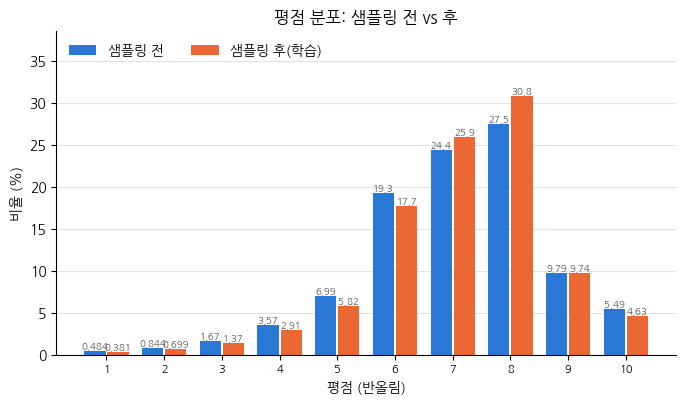

/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: Pyp

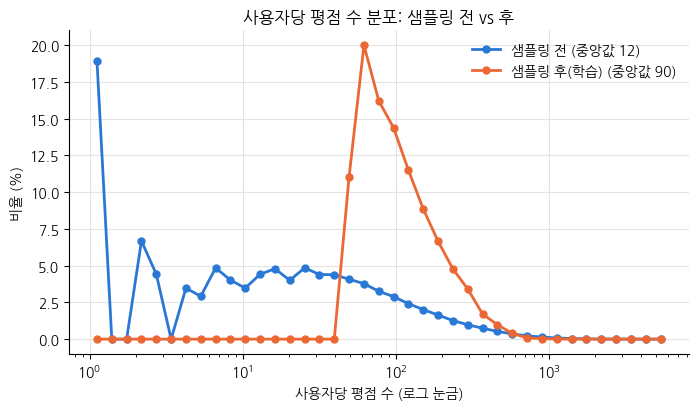

/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2197: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  return self._math_expression.parseString(toks[0][1:-1], parseAll=True)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/matplotlib/_math

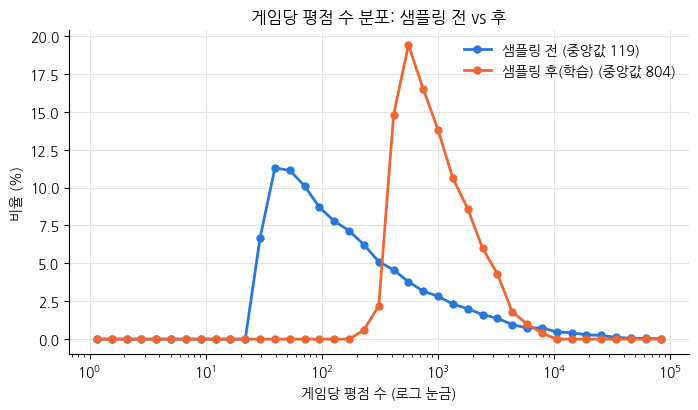

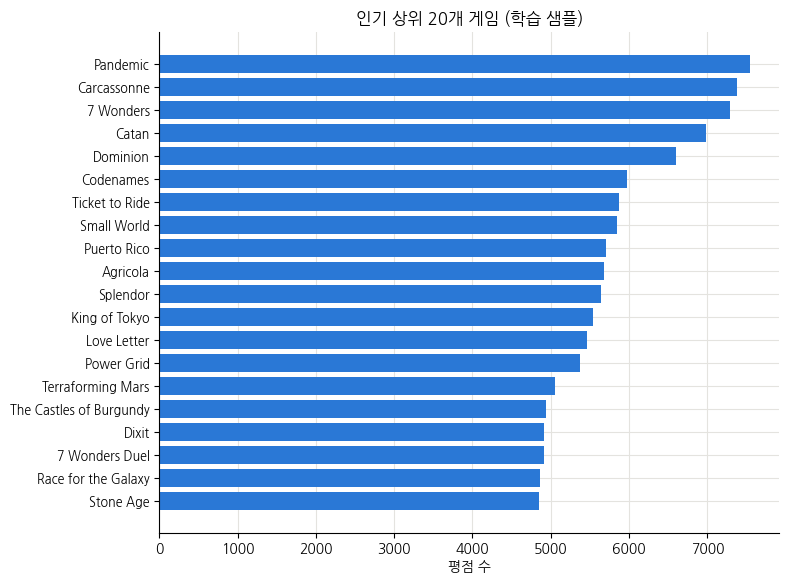

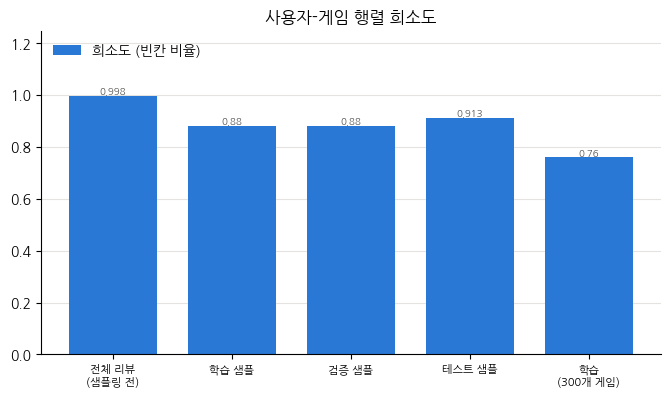

,데이터,사용자수,게임수,평점수,희소도,평균평점,선호비율_8점이상
0,전체 리뷰(샘플링 전),351048,19330,15823190,0.9977,7.0549,0.3723
1,학습 샘플,10000,1000,1196960,0.8803,7.1427,0.3825
2,검증 샘플,2000,1000,239625,0.8802,7.1189,0.3778
3,테스트 샘플,2945,1000,254686,0.9135,7.2922,0.4102
4,학습(300개 게임),10000,300,719517,0.7602,7.2785,0.4226


2272

In [25]:
# 2-5. ▶ EDA 실행 후 큰 원본은 메모리에서 지움
g300 = pd.read_csv(PROC / "games300.csv")["game_id"].to_numpy()
table, top20 = eda(reviews, samples["train"], NAMES,
                   {"전체 리뷰(샘플링 전)": reviews, "학습 샘플": samples["train"], "검증 샘플": samples["val"],
                    "테스트 샘플": samples["test"], "학습(300개 게임)": samples["train"][samples["train"]["game_id"].isin(g300)]})
display(table)
del reviews, test, train_pool, val_pool, test_pool, is_train
gc.collect()

## 3. 평가 틀과 인기 순 기준선
검증·테스트 사용자는 학습에 없던 사람이다. 각자의 평점을 무작위로 **80% 입력 / 20% 정답**으로 나누고,
정답 = 20% 중 **8점 이상** 준 게임. 추천 10개가 정답을 얼마나 맞히는지 NDCG@10·Precision@10·Recall@10 으로 잰다.
모든 추천 함수는 `recommend(입력 평점, n) → 게임 ID 리스트` 형태라 `evaluate()` 하나로 평가한다.

> 기존 코드와 달라진 점: `evaluate()` 가 사용자별 점수(`scores`)도 돌려준다(14장 부트스트랩용).
> 또 추천 1건당 시간(`rec_ms`)을 실제로 평가한 사용자 수로 나누도록 고쳤다(동점일 때 설정 고르는 데만 쓰는 값).

In [26]:
# 3-1. 입력·정답 분할 함수
LIKE = 8.0   # 선호 기준 점수 (평가 정답 기준은 항상 8점)
N = 10       # 추천 개수


def split_input_truth(df, seed=42):
    """사용자별 (입력 평점 Series, 정답 게임 집합). Series.name = (사용자, 시드)는 kNN 캐시 키."""
    rng = np.random.default_rng(seed)
    out = []
    for user, g in df.sort_values(["user", "game_id"]).groupby("user", sort=True):
        perm = rng.permutation(len(g))
        n_hold = int(round(len(g) * 0.2))
        hold, inp = g.iloc[perm[:n_hold]], g.iloc[perm[n_hold:]]
        ratings = pd.Series(inp["rating"].to_numpy(), index=inp["game_id"].to_numpy(), name=(user, seed))
        out.append((ratings, set(hold.loc[hold["rating"] >= LIKE, "game_id"])))
    return out

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [27]:
# 3-2. 공통 데이터 캐시 (샘플·게임 목록·인기 순위를 한 번만 읽고, 규칙·모델·분할도 여기에 보관)
_CTX = {}


def context():
    # 학습 데이터나 게임 목록을 바꿨다면 _CTX.clear() 후 다시 호출해야 한다.
    # 모델뿐 아니라 기존 입력 분할과 추천 설정도 이 딕셔너리에 남아 있다.
    if not _CTX:
        train, val, test, g1000, g300 = load_samples()
        pop, s300 = popularity(train), set(g300)
        _CTX.update(train=train, val=val, test=test, g1000=g1000, g300=g300, pop=pop,
                    pop300=[g for g in pop if g in s300], rules={}, models={}, splits={})
    return _CTX


def get_split(ctx, name, seed=42):
    """'val'/'test' 사용자의 입력·정답 분할 (시드별 캐시)."""
    if (name, seed) not in ctx["splits"]:
        ctx["splits"][(name, seed)] = split_input_truth(ctx[name], seed)
    return ctx["splits"][(name, seed)]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [28]:
# 3-3. 확인용 도우미 (게임 이름 표, 추천 결과 표)
def names_of(ids):
    return [NAMES.get(g, g) for g in ids]


def show_recs(recs, truth, title=""):
    """추천 10개를 이름·정답 적중 여부로 보여 준다."""
    df = pd.DataFrame({"게임": names_of(recs), "정답 적중": ["✔" if g in truth else "" for g in recs]},
                      index=pd.RangeIndex(1, len(recs) + 1, name="순위"))
    print(f"{title}  → 10개 중 {sum(g in truth for g in recs)}개 적중")
    display(df)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [29]:
# 3-4. 🔍 예시 사용자 한 명의 입력·정답 (이 사람을 4~7장에서 계속 따라간다)
ctx = context()
val42 = get_split(ctx, "val", 42)
s300 = set(ctx["g300"])
EX_INP, EX_TRUTH = next((inp, t) for inp, t in val42 if len(t & s300) >= 3)   # 300개 안 정답이 3개 이상인 첫 사용자
print(f"검증 사용자 {len(val42):,}명 중 예시: {EX_INP.name[0]}")
print(f"입력 평점 {len(EX_INP)}개 (8점 이상 {int((EX_INP >= LIKE).sum())}개), 정답(숨긴 20% 중 8점 이상) {len(EX_TRUTH)}개")
display(pd.DataFrame({"게임": names_of(EX_INP.index), "평점": EX_INP.values}).sort_values("평점", ascending=False).head(10))
print("정답 게임:", ", ".join(names_of(EX_TRUTH)))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


검증 사용자 2,000명 중 예시: 13rett
입력 평점 68개 (8점 이상 18개), 정답(숨긴 20% 중 8점 이상) 3개


,게임,평점
45,Pandemic Legacy: Season 1,9.0
3,Power Grid,8.0
6,Azul,8.0
19,Two Rooms and a Boom,8.0
52,Splendor,8.0
24,Puerto Rico,8.0
57,Android: Netrunner,8.0
10,Queendomino,8.0
16,Catan,8.0
17,Pandemic,8.0


정답 게임: Secret Hitler, Bohnanza, The Castles of Burgundy


In [30]:
# 3-5. 순위 지표 함수
def ranking_metrics(recs, truth):
    """NDCG@10, Precision@10, Recall@10 (이진 관련도, Precision 분모는 항상 10)."""
    hits = np.array([g in truth for g in recs[:N]], dtype=float)
    dcg = (hits / np.log2(np.arange(2, len(hits) + 2))).sum()
    idcg = (1 / np.log2(np.arange(2, min(len(truth), N) + 2))).sum()
    return dcg / idcg, hits.sum() / N, hits.sum() / len(truth)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [31]:
# 3-6. 🔍 지표 계산 예: 정답이 4개이고 추천 1위·5위가 맞은 경우 (같은 2개 적중이어도 위에 있을수록 NDCG 가 높다)
toy_truth = {"A", "B", "C", "D"}
for recs in (["A", "x", "x", "x", "B", "x", "x", "x", "x", "x"], ["x", "x", "x", "x", "x", "x", "x", "x", "A", "B"]):
    ndcg, prec, rec = ranking_metrics(recs, toy_truth)
    print(f"적중 위치 {[i + 1 for i, g in enumerate(recs) if g in toy_truth]} → NDCG {ndcg:.3f}, Precision {prec:.2f}, Recall {rec:.2f}")

적중 위치 [1, 5] → NDCG 0.541, Precision 0.20, Recall 0.50
적중 위치 [9, 10] → NDCG 0.230, Precision 0.20, Recall 0.50


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [32]:
# 3-7. 평가 함수
def evaluate(recommend, split, candidates):
    """사용자 평균 점수. 정답도 후보 안으로 제한하고, 후보 안에 정답이 없는 사용자는 제외.
    scores = 평가한 사용자별 (NDCG, Precision, Recall) 배열 (부트스트랩용)."""
    cand, t0 = set(candidates), time.time()
    s = np.array([ranking_metrics(recommend(inp, N), truth & cand)
                  for inp, truth in tqdm(split, desc="사용자별 추천·채점", leave=False, mininterval=1) if truth & cand])
    return dict(ndcg=s[:, 0].mean(), precision=s[:, 1].mean(), recall=s[:, 2].mean(), n_eval=len(s),
                n_excluded=len(split) - len(s), rec_ms=(time.time() - t0) / len(s) * 1000, scores=s)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [33]:
# 3-8. 인기 순 채우기·인기 순 기준선 함수
def fill_popular(recs, inp, pop_order, n, stats):
    """추천이 n개보다 적으면 인기 순으로 채우고, 채운 칸 수를 stats 에 기록."""
    # filled는 실제로 추가한 수가 아니라 모델 추천에서 부족했던 칸 수다.
    # 후보가 충분하다는 전제에서 filled / slots를 인기 순 채움 비율로 쓴다.
    stats["slots"] = stats.get("slots", 0) + n
    stats["filled"] = stats.get("filled", 0) + max(0, n - len(recs))
    # 낮은 점수를 준 게임도 이미 평가한 게임이므로 다시 추천하지 않는다.
    # pop_order는 중복 없는 게임 목록이며, 호출 전에 추천 후보 범위로 제한해야 한다.
    seen = set(recs) | set(inp.index)
    for g in pop_order:
        if len(recs) >= n:
            break
        if g not in seen:
            recs.append(g)
    return recs


def make_popular(pop_order):
    """기준선: 인기 순 추천 (입력한 게임 제외)."""
    def recommend(inp, n=N):
        return fill_popular([], inp, pop_order, n, {})
    return recommend

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [34]:
# 3-9. 🔍 인기 순 기준선: 예시 사용자 추천과 검증 전체 점수
show_recs(make_popular(ctx["pop300"])(EX_INP), EX_TRUTH, "인기 순 (후보 300개)")
r = evaluate(make_popular(ctx["pop"]), val42, ctx["g1000"])
print(f"검증 전체 (후보 1,000개): NDCG {r['ndcg']:.4f}, Precision {r['precision']:.4f}, Recall {r['recall']:.4f}, "
      f"평가 {r['n_eval']}명 / 제외 {r['n_excluded']}명")

인기 순 (후보 300개)  → 10개 중 1개 적중


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,게임,정답 적중
순위,,
1,Carcassonne,
2,Ticket to Ride,
3,Agricola,
4,Terraforming Mars,
5,The Castles of Burgundy,✔
6,Dixit,
7,Race for the Galaxy,
8,Stone Age,
9,Lords of Waterdeep,


사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

검증 전체 (후보 1,000개): NDCG 0.1626, Precision 0.1181, Recall 0.1405, 평가 1987명 / 제외 13명


## 4. kNN 협업 필터링
빈칸은 0점이 아니라 "관측 안 됨". 두 사용자(또는 두 게임)가 **함께 평가한 항목만으로** 유사도를 구하고,
공통 평가가 기준(기본 5개) 미만이면 유사도 0. 유사도가 양수인 이웃 중 상위 K개로 예상 평점을 계산한다.

- 코사인: 이웃 평점의 유사도 가중 평균
- 피어슨: (이웃 평점 − 이웃 평균)의 유사도 가중 평균 + 대상 평균
- 사용자 기반: 나와 비슷한 학습 사용자 K명 / 아이템 기반: 각 게임과 비슷한 게임 K개 중 내가 평가한 것

In [35]:
# 4-1. 유사도 함수
K_MAX = 80   # 이웃은 80개까지 한 번 구해 두고 작은 K 는 앞에서 잘라 쓴다


def similarity(A, B, kind="cosine", min_common=5):
    """A, B 행끼리 유사도. 공통 평가 항목이 min_common 개 미만이면 0.
    피어슨은 두 행이 함께 평가한 항목만으로 계산(공통 항목 위의 합을 행렬 곱으로)."""
    # A와 B는 열 순서가 같은 희소 행렬이다. 반환 행렬의 (a, b)는 A의 a행과 B의 b행 유사도다.
    # 원본 평점은 1~10점이므로 0을 미평가 표시로 쓸 수 있다. 관측 여부를 따로 만들어 공통 개수를 센다.
    Ab, Bb = (A > 0).astype(np.float64), (B > 0).astype(np.float64)
    n = (Ab @ Bb.T).toarray()                                  # 공통 평가 항목 수
    if kind == "cosine":
        # 코사인은 미평가 칸을 0으로 둔 전체 벡터로 계산한다.
        # 분자는 공통 평가 항목에서만 생기지만, 벡터의 크기에는 각자의 모든 평점이 들어간다.
        S = cosine_similarity(A, B)
    else:
        # 피어슨의 합과 제곱합은 두 행이 모두 평가한 항목으로 제한한다.
        # 사용자 전체 평균을 미리 빼면 이 공통 항목 기준의 상관계수와 달라진다.
        sx, sy = (A @ Bb.T).toarray(), (Ab @ B.T).toarray()    # Σx, Σy
        sxy = (A @ B.T).toarray()                              # Σxy
        sxx, syy = (A.multiply(A) @ Bb.T).toarray(), (Ab @ B.multiply(B).T).toarray()   # Σx², Σy²
        with np.errstate(divide="ignore", invalid="ignore"):
            cov = sxy - sx * sy / n
            S = cov / np.sqrt((sxx - sx ** 2 / n) * (syy - sy ** 2 / n))
    # 공통 평가가 없거나 공통 평점이 일정하면 피어슨이 NaN이 될 수 있어 0으로 바꾼다.
    # min_common은 두 유사도 모두에 적용한다. 음수 유사도는 여기서 남기고 이웃 선택 때 제외한다.
    S = np.nan_to_num(S)
    S[n < min_common] = 0.0
    return S

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [36]:
# 4-2. kNN 모델 만들기 함수
def knn_fit(train, games, kind, sim, min_common=5):
    """학습 평점 행렬로 모델(dict)을 만든다. 아이템 기반은 게임별 이웃 목록까지 계산."""
    # train에는 games에 포함된 게임만 있어야 한다. 외부 게임 ID가 있으면 gidx 매핑에서 누락된다.
    # R의 행은 정렬된 사용자 순서, 열은 전달받은 games 순서다. 예측 배열도 이 열 순서를 따른다.
    users = np.sort(train["user"].unique())
    gidx = {g: i for i, g in enumerate(games)}
    R = sp.csr_matrix((train["rating"].to_numpy(np.float64),
                       (np.searchsorted(users, train["user"]), train["game_id"].map(gidx))),
                      shape=(len(users), len(games)))
    # CSR의 indptr 차이로 각 행의 관측 개수를 구한다. 미평가 칸을 평균의 분모에 넣지 않는다.
    cnt = np.diff(R.indptr)                                    # 사용자별 평점 수
    m = dict(kind=kind, sim=sim, min_common=min_common, R=R, games=np.asarray(games), gidx=gidx,
             user_mean=np.asarray(R.sum(axis=1)).ravel() / np.maximum(cnt, 1), cache={})
    if kind == "item":
        Rt = R.T.tocsr()                                       # 게임 × 사용자
        m["item_mean"] = np.asarray(Rt.sum(axis=1)).ravel() / np.maximum(np.diff(Rt.indptr), 1)
        S = similarity(Rt, Rt, sim, min_common)
        # 게임 자신이 이웃 목록의 첫 자리를 차지하지 않도록 자기 유사도를 제거한다.
        np.fill_diagonal(S, 0)
        # 아이템 이웃은 학습 시 K_MAX개까지 저장한다. K를 바꿀 때는 이 목록의 앞부분을 사용한다.
        # stable 정렬은 유사도가 같을 때 games의 기존 순서를 유지한다.
        order = np.argsort(-S, axis=1, kind="stable")[:, :K_MAX]
        m["nb_idx"] = order                                    # 게임별 이웃 (유사도 높은 순)
        m["nb_sim"] = np.maximum(np.take_along_axis(S, order, axis=1), 0)   # 음수는 0 (양수만 사용)
    return m


def knn_model(ctx, cfg):
    """(종류, 유사도, 공통 평점 기준)별 kNN 모델을 한 번만 만든다."""
    # K는 이웃 목록을 자르는 데만 쓰므로 캐시 키에서 제외한다.
    # K_MAX를 늘린 경우에는 기존 모델을 지우고 다시 만들어야 더 긴 이웃 목록이 반영된다.
    key = (cfg["kind"], cfg["sim"], int(cfg["min_common"]))   # 표에서 꺼낸 값은 실수일 수 있어 int
    if key not in ctx["models"]:
        ctx["models"][key] = knn_fit(ctx["train"], ctx["g1000"], *key)
    return ctx["models"][key]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [37]:
# 4-3. 🔍 평점 행렬과 아이템 기반 이웃 (아이템 기반 · 피어슨 · 공통 평점 5)
m_item = knn_model(ctx, dict(kind="item", sim="pearson", min_common=5))
R = m_item["R"]
print(f"평점 행렬: 사용자 {R.shape[0]:,} × 게임 {R.shape[1]:,}, 채워진 칸 {R.nnz:,}개 ({R.nnz / (R.shape[0] * R.shape[1]):.1%})")

g0 = ctx["pop"][0]                                             # 가장 인기 있는 게임의 이웃 보기
i0 = m_item["gidx"][g0]
nb = m_item["nb_idx"][i0][:10]
print(f"'{NAMES.get(g0, g0)}' 와 가장 비슷한 게임 10개 (피어슨)")
display(pd.DataFrame({"게임": names_of(m_item["games"][nb]), "유사도": m_item["nb_sim"][i0][:10].round(3)},
                     index=pd.RangeIndex(1, 11, name="순위")))

# 같은 두 게임의 코사인·피어슨 비교
g1 = m_item["games"][nb[0]]
Rt = R.T.tocsr()
a, b = Rt[[i0]], Rt[[m_item["gidx"][g1]]]
print(f"'{NAMES.get(g0, g0)}' vs '{NAMES.get(g1, g1)}': 함께 평가한 사용자 {int(((a > 0).multiply(b > 0)).sum())}명, "
      f"코사인 {similarity(a, b, 'cosine')[0, 0]:.3f}, 피어슨 {similarity(a, b, 'pearson')[0, 0]:.3f}")

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


평점 행렬: 사용자 10,000 × 게임 1,000, 채워진 칸 1,196,960개 (12.0%)
'Pandemic' 와 가장 비슷한 게임 10개 (피어슨)


,게임,유사도
순위,,
1,Pandemic: Iberia,0.575
2,Pandemic: Reign of Cthulhu,0.501
3,Pandemic Legacy: Season 1,0.493
4,Pandemic: Fall of Rome,0.487
5,Forbidden Island,0.469
6,Black Orchestra,0.448
7,Forbidden Desert,0.429
8,Shadows of Brimstone: City of the Ancients,0.413
9,Flash Point: Fire Rescue,0.402


'Pandemic' vs 'Pandemic: Iberia': 함께 평가한 사용자 738명, 코사인 0.306, 피어슨 0.575


In [38]:
# 4-4. 사용자 기반 이웃 찾기 함수
def user_neighbors(m, inp):
    """새 사용자와 학습 사용자의 유사도 → 양수인 상위 80명 (입력별로 캐시)."""
    # inp의 인덱스는 BGG 게임 ID이며, 모두 m["gidx"]에 있어야 한다.
    # 캐시는 평점 내용 대신 inp.name으로 구분한다. 입력이 바뀌면 name도 바꾸거나 캐시를 비워야 한다.
    # 검증에서는 (사용자, 분할 시드), 직접 추천에서는 입력 평점까지 포함한 튜플을 name으로 쓴다.
    if inp.name not in m["cache"]:
        x = sp.csr_matrix((inp.to_numpy(np.float64), ([0] * len(inp), [m["gidx"][g] for g in inp.index])),
                          shape=(1, len(m["games"])))
        s = similarity(x, m["R"], m["sim"], m["min_common"])[0]
        # 양수 유사도의 학습 사용자만 남긴다. 실제 저장 상한은 고정된 80이 아니라 현재 K_MAX다.
        idx = np.argsort(-s, kind="stable")[:K_MAX]
        idx = idx[s[idx] > 0]
        m["cache"][inp.name] = (idx, s[idx])
    return m["cache"][inp.name]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [39]:
# 4-5. 예상 평점 함수
def knn_predict(m, inp, K):
    """1,000개 게임의 예상 평점 (못 구하면 NaN)."""
    with np.errstate(divide="ignore", invalid="ignore"):
        if m["kind"] == "user":                                # 이웃 K명 중 그 게임을 평가한 사람만
            idx, s = user_neighbors(m, inp)
            # 사용자 전체에서 상위 K명을 먼저 고른 뒤, 게임별로 평점이 있는 이웃만 계산에 참여시킨다.
            # 어떤 게임을 평가한 이웃이 부족해도 K 밖의 사용자를 추가로 가져오지는 않는다.
            idx, s = idx[:K], s[:K]
            Rn = m["R"][idx].toarray()
            rated = Rn > 0
            if m["sim"] == "cosine":
                num = s @ Rn
            else:
                # 이웃의 평점 성향을 빼고 편차만 합산한다. rated를 곱해 미평가 칸이 음수 편차로 들어가지 않게 한다.
                # 여기서는 이웃의 전체 관측 평균을 쓴다. 유사도 계산에 쓴 공통 항목 평균과는 구분한다.
                num = s @ ((Rn - m["user_mean"][idx, None]) * rated)
            # 게임마다 참여한 이웃이 다르므로 분모도 게임별 유사도 합으로 계산한다.
            den = s @ rated
            p = num / den
            if m["sim"] == "pearson":
                p = inp.mean() + p
        else:                                                  # 게임별 이웃 K개 중 내가 평가한 게임만
            r = np.full(len(m["games"]), np.nan)
            r[[m["gidx"][g] for g in inp.index]] = inp.to_numpy()
            # 각 행은 추천 대상 게임, 각 열은 그 게임의 이웃이다. v에는 사용자가 준 이웃 게임 평점이 들어간다.
            idx, s = m["nb_idx"][:, :K], m["nb_sim"][:, :K]
            v = r[idx]
            if m["sim"] == "pearson":
                v = v - m["item_mean"][idx]
            # 사용자가 평가하지 않은 이웃 게임은 가중치를 0으로 두어 분자와 분모에서 모두 뺀다.
            w = np.where(np.isnan(v), 0, s)
            num, den = (w * np.nan_to_num(v)).sum(axis=1), w.sum(axis=1)
            p = num / den
            if m["sim"] == "pearson":
                p = m["item_mean"] + p
    # 근거가 없는 게임을 0점으로 취급하지 않는다. NaN으로 넘기면 추천 단계에서 제외하고 인기 순으로 보충한다.
    # 예상 평점은 순위에 그대로 사용하며, 1~10 범위로 잘라내지 않는다.
    p[den <= 0] = np.nan
    return p

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [40]:
# 4-6. 🔍 예시 사용자: 사용자 기반 이웃과 예상 평점
m_user = knn_model(ctx, dict(kind="user", sim="cosine", min_common=5))
idx, s = user_neighbors(m_user, EX_INP)
print(f"[사용자 기반 · 코사인] 유사도가 양수인 이웃 {len(idx)}명 중 상위 5명의 유사도: {np.round(s[:5], 3)}")

for name, m, K in [("사용자 기반 · 코사인, K=20", m_user, 20), ("아이템 기반 · 피어슨, K=20", m_item, 20)]:
    p = knn_predict(m, EX_INP, K)
    p[np.isin(m["games"], EX_INP.index)] = np.nan             # 이미 평가한 게임은 빼고 보기
    print(f"[{name}] 예상 평점을 구한 게임 {int(np.isfinite(p).sum())}개 / 못 구한 게임 {int(np.isnan(p).sum())}개")
    top = np.argsort(-np.nan_to_num(p, nan=-np.inf))[:10]
    display(pd.DataFrame({"게임": names_of(m["games"][top]), "예상 평점": p[top].round(2),
                          "정답": ["✔" if g in EX_TRUTH else "" for g in m["games"][top]]},
                         index=pd.RangeIndex(1, 11, name="순위")))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


[사용자 기반 · 코사인] 유사도가 양수인 이웃 80명 중 상위 5명의 유사도: [0.49  0.459 0.44  0.437 0.436]
[사용자 기반 · 코사인, K=20] 예상 평점을 구한 게임 411개 / 못 구한 게임 589개


,게임,예상 평점,정답
순위,,,
1,TZAAR,10.00,
2,Crokinole,10.00,
3,Dinosaur Island,10.00,
4,YINSH,10.00,
5,Pandemic Legacy: Season 2,10.00,
6,KeyForge: Call of the Archons,9.50,
7,Robinson Crusoe: Adventures on the Cursed Island,9.36,
8,Spirit Island,9.34,
9,Suburbia,9.24,


[아이템 기반 · 피어슨, K=20] 예상 평점을 구한 게임 358개 / 못 구한 게임 642개


,게임,예상 평점,정답
순위,,,
1,Underwater Cities,8.90,
2,Pandemic Legacy: Season 2,8.73,
3,Indonesia,8.68,
4,Teotihuacan: City of Gods,8.68,
5,Dune,8.59,
6,The Quacks of Quedlinburg,8.53,
7,Twilight Struggle,8.50,
8,Snowdonia,8.48,
9,Five Tribes,8.45,


In [41]:
# 4-7. kNN 추천 함수 (예상 평점 순, 동점은 인기 순, 부족하면 인기 순으로 채움)
def pop_rank(m, pop_order):
    """게임별 인기 순위 (0 = 1위). 점수 동점일 때 정렬 기준."""
    rank = np.full(len(m["games"]), len(pop_order))
    rank[[m["gidx"][g] for g in pop_order if g in m["gidx"]]] = np.arange(len(pop_order))
    return rank


def make_knn_recommender(m, K, pop_order, candidates):
    """예상 평점 상위 10개 추천 (동점은 인기 순, 부족하면 인기 순으로 채움)."""
    cand, rank = np.isin(m["games"], candidates), pop_rank(m, pop_order)
    cset = set(candidates)
    pop_order = [g for g in pop_order if g in cset]
    stats = {}

    def recommend(inp, n=N):
        p = knn_predict(m, inp, K)
        # 점수가 계산됐고 후보에 포함되며 아직 평가하지 않은 게임만 모델 추천에 넣는다.
        ok = np.flatnonzero(np.isfinite(p) & cand & ~np.isin(m["games"], inp.index))
        # lexsort는 마지막 키가 우선이다. -p로 예상 평점 내림차순, 동점일 때 인기 순위를 적용한다.
        top = ok[np.lexsort((rank[ok], -p[ok]))][:n]
        return fill_popular(m["games"][top].tolist(), inp, pop_order, n, stats)

    # 같은 추천 함수를 호출할 때마다 채움 통계가 누적된다. 독립된 평가에는 추천 함수를 새로 만든다.
    recommend.stats = stats
    return recommend

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [42]:
# 4-8. 🔍 예시 사용자 kNN 추천 (후보 300개)
for name, m in [("사용자 기반 · 코사인, K=20", m_user), ("아이템 기반 · 피어슨, K=20", m_item)]:
    show_recs(make_knn_recommender(m, 20, ctx["pop"], ctx["g300"])(EX_INP), EX_TRUTH, name)

사용자 기반 · 코사인, K=20  → 10개 중 0개 적중


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,게임,정답 적중
순위,,
1,Crokinole,
2,Robinson Crusoe: Adventures on the Cursed Island,
3,Spirit Island,
4,Suburbia,
5,Concordia,
6,Viticulture Essential Edition,
7,Star Wars: X-Wing Miniatures Game,
8,Imperial Settlers,
9,Through the Ages: A Story of Civilization,


아이템 기반 · 피어슨, K=20  → 10개 중 0개 적중


,게임,정답 적중
순위,,
1,Teotihuacan: City of Gods,
2,The Quacks of Quedlinburg,
3,Twilight Struggle,
4,Five Tribes,
5,Welcome To...,
6,Inis,
7,Gaia Project,
8,Istanbul,
9,At the Gates of Loyang,


## 5. Apriori 연관 규칙
학습 사용자 1명 = 트랜잭션(장바구니), 선호 기준(기본 8점) 이상 준 게임(300개 중) = 항목. 좋아한 게임이 없는 사용자도 support 분모에 포함.
"A 를 좋아하면 B 도 좋아한다(A → B)" 규칙(max_len=2) 중 Lift > 1 만 쓴다.
가장 낮은 기준(support 0.005, confidence 0.3)으로 한 번만 만들고 높은 기준은 걸러 쓴다(다시 돌린 결과와 같음).

- Support = A·B 를 모두 좋아한 사용자 비율
- Confidence = A 를 좋아한 사용자 중 B 도 좋아한 비율
- Lift = Confidence ÷ (B 를 좋아한 비율). 1보다 크면 우연보다 자주 함께 좋아함

> 기존 코드와 달라진 점: 선호 기준 `like` 를 인자로 받는다(10장에서 7·8·9점 비교). 기본값 8점이면 기존과 같다.

In [43]:
# 5-1. 규칙 찾기 함수
def mine_rules(train, games300, like=LIKE, min_support=0.005, min_conf=0.3):
    """규칙 표 (a, b, support, confidence, lift). like = 트랜잭션에 넣을 선호 기준 점수."""
    rated = train[train["game_id"].isin(games300)].assign(liked=lambda d: d["rating"] >= like)
    trans = rated.pivot_table(index="user", columns="game_id", values="liked", aggfunc="any", fill_value=False)
    # 300개 게임을 평가하지 않은 사용자도 빈 장바구니로 포함한다.
    # 이 행을 빼면 support의 분모가 줄어 규칙이 실제보다 자주 등장한 것으로 계산된다.
    trans = trans.reindex(index=sorted(train["user"].unique()), columns=sorted(games300), fill_value=False)
    trans = trans.astype(bool)                                 # 행 = 학습 사용자 전원 (support 분모)
    # max_len=2라서 A → B 형태의 단일 게임 규칙만 만든다.
    # 여러 게임을 전제로 하는 규칙으로 확장하려면 아래 a, b 추출 방식도 함께 바꿔야 한다.
    freq = apriori(trans, min_support=min_support, use_colnames=True, max_len=2)
    rules = association_rules(freq, num_itemsets=len(trans), metric="confidence", min_threshold=min_conf)
    # B가 원래 인기 있는 정도보다 A를 좋아한 집단에서 B의 선호 비율이 더 높은 규칙만 남긴다.
    rules = rules[rules["lift"] > 1]
    out = pd.DataFrame({"a": rules["antecedents"].map(lambda s: next(iter(s))),
                        "b": rules["consequents"].map(lambda s: next(iter(s))),
                        "support": rules["support"], "confidence": rules["confidence"],
                        "lift": rules["lift"]}).reset_index(drop=True)
    return out


def rules_for(ctx, like=LIKE):
    """선호 기준별 규칙 표 (한 번만 계산)."""
    # 선호 기준이 달라지면 장바구니부터 달라지므로 like별로 다시 채굴한다.
    # 캐시는 support 0.005, confidence 0.3에서 만든 규칙이다. 이보다 낮은 기준을 탐색하려면 재채굴해야 한다.
    if like not in ctx["rules"]:
        ctx["rules"][like] = mine_rules(ctx["train"], ctx["g300"], like)
    return ctx["rules"][like]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [44]:
# 5-2. 🔍 규칙 찾기 결과 (선호 기준 8점)
t0 = time.time()
rules8 = rules_for(ctx, 8.0)
liked_per_user = ctx["train"][ctx["train"]["game_id"].isin(ctx["g300"])].groupby("user")["rating"].apply(lambda r: (r >= 8).sum())
print(f"트랜잭션: 학습 사용자 {ctx['train']['user'].nunique():,}명, 사용자당 좋아한 게임 평균 {liked_per_user.mean():.1f}개")
print(f"규칙 {len(rules8):,}개 (support ≥ 0.005, confidence ≥ 0.3, lift > 1), {time.time() - t0:.1f}초")
view = rules8.sort_values("confidence", ascending=False).head(10)
display(view.assign(A=names_of(view["a"]), B=names_of(view["b"]))[["A", "B", "support", "confidence", "lift"]].round(3))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


트랜잭션: 학습 사용자 10,000명, 사용자당 좋아한 게임 평균 30.4개
규칙 7,322개 (support ≥ 0.005, confidence ≥ 0.3, lift > 1), 2.8초


,A,B,support,confidence,lift
3344,Dominion: Intrigue,Dominion,0.141,0.873,2.891
4525,Bora Bora,The Castles of Burgundy,0.054,0.819,2.399
4497,Trajan,The Castles of Burgundy,0.089,0.780,2.283
736,The Princes of Florence,Puerto Rico,0.071,0.767,2.179
7027,Codenames: Pictures,Codenames,0.056,0.766,2.523
1325,Goa,Puerto Rico,0.058,0.749,2.128
7045,Codenames: Duet,Codenames,0.051,0.739,2.434
2947,Ora et Labora,Agricola,0.054,0.736,2.118
1339,Caylus,Puerto Rico,0.126,0.726,2.061
1367,In the Year of the Dragon,Puerto Rico,0.047,0.720,2.045


In [45]:
# 5-3. 규칙 추천 함수
def make_rule_recommender(rules, min_support, min_conf, sort_by, pop_order, like=LIKE):
    """입력에서 좋아한(like 점 이상) 게임이 A 인 규칙의 B 를 추천. 정렬: sort_by → 다른 지표 → 게임 ID.
    같은 B 는 가장 높은 규칙만 쓰고, 부족하면 인기 순으로 채운다."""
    other = "lift" if sort_by == "confidence" else "confidence"
    r = rules[(rules["support"] >= min_support) & (rules["confidence"] >= min_conf)]
    # 정렬은 사용자와 무관하므로 한 번만 한다. 이후 같은 B가 여러 번 나오면 첫 규칙이 가장 높은 규칙이다.
    r = r.sort_values([sort_by, other, "b"], ascending=[False, False, True])
    stats = {"n_rules": len(r), "rule_users": 0}

    def recommend(inp, n=N):
        liked = inp.index[inp >= like]
        # 전제 A는 선호 기준 이상인 입력만 사용하고, 결과 B는 낮은 평점을 포함해 이미 평가한 게임을 모두 뺀다.
        sel = r[r["a"].isin(liked) & ~r["b"].isin(inp.index)]
        # 여러 A가 같은 B를 추천해도 규칙 점수를 더하지 않는다. 가장 높은 규칙 하나로 B의 순위를 정한다.
        recs = sel["b"].drop_duplicates().head(n).tolist()
        stats["rule_users"] += bool(recs)                      # 규칙 추천을 받은 사용자 수
        return fill_popular(recs, inp, pop_order, n, stats)

    recommend.stats = stats
    return recommend

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [46]:
# 5-4. 🔍 예시 사용자: 어떤 규칙이 적용됐고 무엇이 추천됐나
liked = EX_INP.index[EX_INP >= 8]
fired = rules8[rules8["a"].isin(liked) & ~rules8["b"].isin(EX_INP.index)].sort_values("confidence", ascending=False)
print(f"좋아한 게임 {len(liked)}개 → 적용되는 규칙 {len(fired)}개, 추천 후보 게임 {fired['b'].nunique()}개")
best = fired.drop_duplicates("b").head(10)                       # 같은 B 는 가장 높은 규칙만
display(best.assign(근거_A=names_of(best["a"]), 추천_B=names_of(best["b"]),
                    정답=["✔" if g in EX_TRUTH else "" for g in best["b"]])[["근거_A", "추천_B", "confidence", "lift", "정답"]].round(3))
show_recs(make_rule_recommender(rules8, 0.005, 0.3, "confidence", ctx["pop300"])(EX_INP), EX_TRUTH,
          "연관 규칙 (support 0.005, confidence 0.3, Confidence 우선)")

좋아한 게임 18개 → 적용되는 규칙 151개, 추천 후보 게임 29개


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,근거_A,추천_B,confidence,lift,정답
1364,Puerto Rico,Agricola,0.557,1.604,
6653,Azul,Terraforming Mars,0.547,1.434,
4511,Terra Mystica,The Castles of Burgundy,0.527,1.542,✔
6689,Captain Sonar,Scythe,0.510,1.641,
3922,Jaipur,Patchwork,0.474,2.035,
132,Catan,Carcassonne,0.470,1.779,
5187,Terra Mystica,Tzolk'in: The Mayan Calendar,0.436,1.920,
1896,Android: Netrunner,Twilight Struggle,0.435,1.707,
2537,Dominion: Intrigue,Race for the Galaxy,0.433,1.627,
5260,Terra Mystica,Great Western Trail,0.400,1.702,


연관 규칙 (support 0.005, confidence 0.3, Confidence 우선)  → 10개 중 1개 적중


,게임,정답 적중
순위,,
1,Agricola,
2,Terraforming Mars,
3,The Castles of Burgundy,✔
4,Scythe,
5,Patchwork,
6,Carcassonne,
7,Tzolk'in: The Mayan Calendar,
8,Twilight Struggle,
9,Race for the Galaxy,


## 6. 하이브리드
점수 = w × kNN 예상 평점 + (1 − w) × 규칙 점수 (둘 다 사용자별 0~1 정규화).
규칙 점수는 B 별 최고 confidence(또는 lift). 한쪽만 있으면 다른 쪽은 0, 둘 다 없으면 제외.

In [47]:
# 6-1. 0~1 정규화 함수
def minmax(x):
    """점수가 있는 칸만 0~1 정규화 (모두 같으면 1, 없는 칸은 NaN)."""
    ok = np.isfinite(x)
    # 점수가 없는 NaN과 정규화 결과가 0인 최저 점수는 의미가 다르므로 결측 표시는 유지한다.
    z = np.full(len(x), np.nan)
    if ok.any():
        lo, hi = x[ok].min(), x[ok].max()
        # 유효 점수가 하나뿐이거나 모두 같으면 1을 준다. 이 경우에도 해당 모델의 추천 근거는 있는 것으로 처리한다.
        z[ok] = (x[ok] - lo) / (hi - lo) if hi > lo else 1.0
    return z

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [48]:
# 6-2. 하이브리드 추천 함수
def make_hybrid_recommender(m, K, rules, rule_cfg, w, pop_order, candidates):
    """하이브리드 추천 함수 (m = kNN 모델, w = kNN 가중치)."""
    games, gidx = m["games"], m["gidx"]
    cand, rank, cset = np.isin(games, candidates), pop_rank(m, pop_order), set(candidates)
    r = rules[(rules["support"] >= rule_cfg["min_support"]) & (rules["confidence"] >= rule_cfg["min_conf"])]
    like = rule_cfg.get("like", LIKE)
    pop_c = [g for g in pop_order if g in cset]
    stats = {}

    def recommend(inp, n=N):
        ok = cand & ~np.isin(games, inp.index)                 # 후보 안, 입력 게임 제외
        # 정규화 전에 추천 후보 밖의 게임과 이미 평가한 게임을 가린다. 이들의 점수가 최솟값·최댓값에 섞이지 않게 한다.
        ks = np.where(ok, knn_predict(m, inp, K), np.nan)
        # 규칙 쪽은 게임별 최고 confidence 또는 lift를 점수로 사용한다. 적용된 규칙 수는 가산하지 않는다.
        best = r[r["a"].isin(inp.index[inp >= like])].groupby("b")[rule_cfg["sort_by"]].max()
        rs = np.full(len(games), np.nan)
        rs[[gidx[b] for b in best.index]] = best.to_numpy()
        rs[~ok] = np.nan
        # 예상 평점과 confidence/lift는 단위가 다르므로 사용자별 유효 후보 안에서 각각 0~1로 맞춘다.
        # 정규화 범위가 사용자마다 달라 이 점수를 사용자 간 선호 강도 비교에 쓰면 안 된다.
        kz, rz = minmax(ks), minmax(rs)
        # 한쪽 점수만 있으면 다른 쪽은 0으로 더한다. 남은 모델의 가중치를 1로 다시 맞추지는 않는다.
        h = w * np.nan_to_num(kz) + (1 - w) * np.nan_to_num(rz)
        # 양쪽 모두 근거가 없는 게임은 다시 NaN으로 표시한다. 유효한 0점 후보와 구분한 뒤 인기 순 보충에 맡긴다.
        h[np.isnan(kz) & np.isnan(rz)] = np.nan
        top = np.flatnonzero(np.isfinite(h))
        top = top[np.lexsort((rank[top], -h[top]))][:n]
        return fill_popular(games[top].tolist(), inp, pop_c, n, stats)

    recommend.stats = stats
    return recommend

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [49]:
# 6-3. 🔍 예시 사용자 하이브리드 추천 (아이템 기반 · 피어슨 K=20 + 규칙, 후보 300개)
demo_rule_cfg = dict(min_support=0.005, min_conf=0.3, sort_by="confidence", like=8.0)
for w in (0.25, 0.75):
    show_recs(make_hybrid_recommender(m_item, 20, rules8, demo_rule_cfg, w, ctx["pop"], ctx["g300"])(EX_INP), EX_TRUTH,
              f"하이브리드 w={w} (kNN 비중)")

하이브리드 w=0.25 (kNN 비중)  → 10개 중 1개 적중


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,게임,정답 적중
순위,,
1,Agricola,
2,Terraforming Mars,
3,The Castles of Burgundy,✔
4,Carcassonne,
5,Twilight Struggle,
6,Scythe,
7,Patchwork,
8,Caverna: The Cave Farmers,
9,Five Tribes,


하이브리드 w=0.75 (kNN 비중)  → 10개 중 0개 적중


,게임,정답 적중
순위,,
1,Agricola,
2,Twilight Struggle,
3,Five Tribes,
4,Teotihuacan: City of Gods,
5,The Quacks of Quedlinburg,
6,Welcome To...,
7,Inis,
8,Gaia Project,
9,Caverna: The Cave Farmers,


## 7. 🆕 행렬 분해 (기획서 4장)
예측 평점 = 전체 평균 μ + 사용자 편향 b<sub>u</sub> + 게임 편향 b<sub>i</sub> + 사용자 요인 p<sub>u</sub> · 게임 요인 q<sub>i</sub>

- **학습**: 학습 사용자 평점을 하나씩 돌며 확률적 경사하강법(SGD)으로 갱신하고, 모든 값에 L2 정규화를 건다. 반복문은 `numba` 로 컴파일해 빠르게 돈다.
- **새 사용자(검증·테스트)**: 학습에 없던 사람이라 사용자 요인이 없다. 게임 쪽 값(q<sub>i</sub>·b<sub>i</sub>)은 고정하고, **입력 평점(80%)만으로** b<sub>u</sub>·p<sub>u</sub> 를 릿지 회귀로 한 번에 푼다. 숨겨 둔 정답은 쓰지 않는다. 정규화 강도는 학습 때와 같게(평점 1개당 λ) 맞췄다.
- **추천**: 후보 게임 중 예상 평점 상위 10개. 모든 게임에 점수가 나오므로 인기 순 채움이 거의 없다.
- 후보 설정: 잠재 차원 20·50·100 × 정규화 강도 0.001·0.01·0.1 (12장에서 검증으로 선택). 학습률 0.005, 30회 반복은 고정.

In [50]:
# 7-1. 경사하강 한 바퀴·RMSE 함수 (numba 로 컴파일, 처음 호출 때 몇 초 걸림)
MF_DIMS = [20, 50, 100]          # 잠재 차원 후보
MF_REGS = [0.001, 0.01, 0.1]     # L2 정규화 강도 후보
MF_EPOCHS = 30                   # 학습 데이터 반복 횟수
MF_LR = 0.005                    # 학습률


@njit
def _sgd_epoch(u, i, r, order, mu, bu, bi, P, Q, lr, reg):
    """평점 하나씩 경사하강: 오차 e = 실제 - 예측, 각 값 += 학습률 × (e × 기울기 - reg × 값)."""
    # u, i는 행렬용 정수 인덱스이고 r은 관측된 평점만 담는다. 미평가 칸을 0점 학습 데이터로 추가하지 않는다.
    # P는 사용자 수 × k, Q는 게임 수 × k이며 bu, bi, P, Q를 제자리에서 갱신한다. mu는 고정한다.
    k = P.shape[1]
    for t in order:
        uu, ii = u[t], i[t]
        pred = mu + bu[uu] + bi[ii]
        for f in range(k):
            pred += P[uu, f] * Q[ii, f]
        e = r[t] - pred
        # 오차를 실제값 - 예측값으로 두었으므로 양수면 예측이 커지는 방향으로 이동한다.
        # reg 항은 편향과 잠재 요인이 계속 커지는 것을 억제하며, 평점 하나를 처리할 때마다 적용된다.
        bu[uu] += lr * (e - reg * bu[uu])
        bi[ii] += lr * (e - reg * bi[ii])
        for f in range(k):
            # P와 Q 모두 갱신 전 값으로 기울기를 구해야 한다. P를 먼저 바꾼 값을 Q 갱신에 쓰지 않도록 보관한다.
            pf, qf = P[uu, f], Q[ii, f]
            P[uu, f] += lr * (e * qf - reg * pf)
            Q[ii, f] += lr * (e * pf - reg * qf)


@njit
def _rmse(u, i, r, mu, bu, bi, P, Q):
    """학습 평점 RMSE."""
    # 학습에 사용한 관측 평점의 오차이며 정규화 항은 포함하지 않는다. 추천 성능 판단은 별도 검증 NDCG로 한다.
    se = 0.0
    for t in range(len(r)):
        pred = mu + bu[u[t]] + bi[i[t]]
        for f in range(P.shape[1]):
            pred += P[u[t], f] * Q[i[t], f]
        se += (r[t] - pred) ** 2
    return np.sqrt(se / len(r))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [51]:
# 7-2. 행렬 분해 학습 함수
def mf_fit(train, games, k, reg, epochs=MF_EPOCHS, lr=MF_LR, seed=SEED):
    """학습 평점으로 행렬 분해 모델(dict). 새 사용자 추천에는 게임 쪽 값(μ, b_i, Q)만 쓴다."""
    users = np.sort(train["user"].unique())
    gidx = {g: j for j, g in enumerate(games)}
    # 사용자명과 BGG ID를 연속 인덱스로 바꾼다. train의 모든 게임 ID가 games에 들어 있다는 전제다.
    u = np.searchsorted(users, train["user"].to_numpy()).astype(np.int64)
    i = train["game_id"].map(gidx).to_numpy(np.int64)
    r = train["rating"].to_numpy(np.float64)
    rng = np.random.default_rng(seed)
    mu = r.mean()
    bu, bi = np.zeros(len(users)), np.zeros(len(games))
    # P와 Q를 모두 0으로 시작하면 서로 곱하는 항의 기울기도 0이 된다. 작은 난수로 시작해 요인을 학습한다.
    P = rng.normal(0, 0.1, (len(users), k))
    Q = rng.normal(0, 0.1, (len(games), k))
    rmse = []
    for _ in tqdm(range(epochs), desc=f"행렬 분해 학습 (차원 {k}, reg {reg})", leave=False):
        _sgd_epoch(u, i, r, rng.permutation(len(r)), mu, bu, bi, P, Q, lr, reg)   # 매 반복 순서를 섞는다
        rmse.append(_rmse(u, i, r, mu, bu, bi, P, Q))
    # 검증·테스트 사용자는 학습 사용자와 다르므로 bu와 P를 저장하지 않는다.
    # 새 사용자의 편향과 요인은 mf_predict에서 입력 평점만으로 다시 추정한다.
    return dict(k=k, reg=reg, games=np.asarray(games), gidx=gidx, mu=mu, bi=bi, Q=Q, train_rmse=rmse)


def mf_model(ctx, cfg):
    """(잠재 차원, 정규화 강도)별 행렬 분해 모델을 한 번만 학습한다."""
    # 캐시 키에는 k와 reg만 들어간다. 학습 데이터, 반복 수, 학습률을 바꾸면 모델 캐시도 비워야 한다.
    # MF_EPOCHS·MF_LR은 mf_fit 정의 시 기본값으로 잡히므로 상수를 바꾼 뒤 이 셀도 다시 실행한다.
    key = ("mf", int(cfg["k"]), float(cfg["reg"]))
    if key not in ctx["models"]:
        ctx["models"][key] = mf_fit(ctx["train"], ctx["g1000"], int(cfg["k"]), float(cfg["reg"]))
    return ctx["models"][key]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [52]:
# 7-3. 🔍 예시 모델 하나 학습 (차원 20, reg 0.01): 반복할수록 학습 RMSE 가 줄어드는지 확인
t0 = time.time()
m_mf = mf_model(ctx, dict(k=20, reg=0.01))
print(f"학습 {time.time() - t0:.1f}초 (numba 컴파일 포함), 전체 평균 μ = {m_mf['mu']:.2f}")
print("학습 RMSE:", " → ".join(f"{x:.3f}" for x in m_mf["train_rmse"][::5]), f"→ {m_mf['train_rmse'][-1]:.3f}")
bi_s = pd.Series(m_mf["bi"], index=m_mf["games"]).sort_values()
print("게임 편향 b_i 가 큰 게임(평균보다 높게 평가받는 게임):", ", ".join(names_of(bi_s.index[-5:][::-1])))
print("게임 편향 b_i 가 작은 게임:", ", ".join(names_of(bi_s.index[:5])))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


행렬 분해 학습 (차원 20, reg 0.01):   0%|          | 0/30 [00:00<?, ?it/s]

학습 12.4초 (numba 컴파일 포함), 전체 평균 μ = 7.14
학습 RMSE: 1.236 → 1.161 → 1.064 → 1.008 → 0.982 → 0.968 → 0.961
게임 편향 b_i 가 큰 게임(평균보다 높게 평가받는 게임): Brass: Birmingham, Twilight Imperium: Fourth Edition, Gloomhaven, Pandemic Legacy: Season 1, Terraforming Mars
게임 편향 b_i 가 작은 게임: Candy Land, Tic-Tac-Toe, Chutes and Ladders, Trouble, The Game of Life


In [53]:
# 7-4. 새 사용자 예상 평점 함수
def mf_predict(m, inp):
    """게임 요인은 고정하고 입력 평점만으로 사용자 편향·요인을 릿지 회귀로 추정 → 1,000개 예상 평점."""
    # 입력 인덱스는 모델에 등록된 게임 ID여야 한다. 반환 배열 순서는 m["games"]와 같다.
    # 전체 평균과 게임 편향을 기본 점수로 두고 새 사용자의 성향만 추가한다.
    base = m["mu"] + m["bi"]
    if len(inp) == 0:                                          # 입력이 없으면 게임 편향만
        return base.copy()
    idx = np.array([m["gidx"][g] for g in inp.index])
    # X의 크기는 입력 평점 수 × (k + 1)이다. 첫 열의 1은 사용자 편향, 나머지 열은 사용자 잠재 요인을 추정한다.
    # 학습된 게임 요인 Q는 고정하며 숨겨 둔 정답 평점은 이 계산에 넣지 않는다.
    X = np.hstack([np.ones((len(idx), 1)), m["Q"][idx]])       # [1, q_i] → [b_u, p_u] 추정
    # 이미 기본 점수로 설명되는 부분을 빼고, 사용자 때문에 생기는 평점 차이를 맞춘다.
    y = inp.to_numpy(np.float64) - base[idx]
    # 학습에서는 평점마다 reg를 적용했으므로 여기서도 reg × 입력 개수로 패널티를 맞춘다.
    # 첫 대각 원소도 포함해 사용자 편향까지 정규화한다. reg가 양수면 입력이 잠재 차원보다 적어도 풀 수 있다.
    A = X.T @ X + m["reg"] * len(idx) * np.eye(X.shape[1])     # 학습 때와 같은 강도 (평점 1개당 reg)
    # 역행렬을 직접 만들지 않고 연립방정식을 푼다. w[0]은 사용자 편향, w[1:]은 사용자 잠재 요인이다.
    w = np.linalg.solve(A, X.T @ y)
    return base + w[0] + m["Q"] @ w[1:]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [54]:
# 7-5. 🔍 예시 사용자: 입력 평점을 얼마나 잘 재현하는지, 예상 평점 상위 게임
p = mf_predict(m_mf, EX_INP)
fit = p[[m_mf["gidx"][g] for g in EX_INP.index]]
print(f"입력 평점 평균 {EX_INP.mean():.2f} / 입력 게임 재현 RMSE {np.sqrt(((fit - EX_INP.values) ** 2).mean()):.3f}")
p[np.isin(m_mf["games"], EX_INP.index)] = -np.inf               # 이미 평가한 게임은 빼고 보기
top = np.argsort(-p)[:10]
display(pd.DataFrame({"게임": names_of(m_mf["games"][top]), "예상 평점": p[top].round(2),
                      "정답": ["✔" if g in EX_TRUTH else "" for g in m_mf["games"][top]]},
                     index=pd.RangeIndex(1, 11, name="순위")))

입력 평점 평균 6.54 / 입력 게임 재현 RMSE 0.574


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,게임,예상 평점,정답
순위,,,
1,Fields of Arle,8.81,
2,Caverna: The Cave Farmers,8.71,
3,Trajan,8.68,
4,Alchemists,8.65,
5,Teotihuacan: City of Gods,8.59,
6,Arkham Horror,8.56,
7,The Castles of Burgundy,8.54,✔
8,The Lord of the Rings: Journeys in Middle-Earth,8.52,
9,Star Wars: Imperial Assault,8.49,


In [55]:
# 7-6. 행렬 분해 추천 함수
def make_mf_recommender(m, pop_order, candidates):
    """예상 평점 상위 10개 추천 (동점은 인기 순, 부족하면 인기 순으로 채움)."""
    cand, rank = np.isin(m["games"], candidates), pop_rank(m, pop_order)
    cset = set(candidates)
    pop_order = [g for g in pop_order if g in cset]
    stats = {}

    def recommend(inp, n=N):
        # 학습된 게임 전체의 점수를 얻은 뒤 후보와 미평가 조건을 적용한다. 점수는 1~10으로 자르지 않고 순위에 쓴다.
        p = mf_predict(m, inp)
        ok = np.flatnonzero(cand & ~np.isin(m["games"], inp.index))
        top = ok[np.lexsort((rank[ok], -p[ok]))][:n]
        # 행렬 분해는 모든 게임에 점수가 나오므로 후보가 충분하면 인기 순 보충이 발생하지 않는다.
        return fill_popular(m["games"][top].tolist(), inp, pop_order, n, stats)

    recommend.stats = stats
    return recommend

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [56]:
# 7-7. 🔍 예시 사용자 행렬 분해 추천 (후보 300개)
show_recs(make_mf_recommender(m_mf, ctx["pop"], ctx["g300"])(EX_INP), EX_TRUTH, "행렬 분해 (차원 20, reg 0.01)")

행렬 분해 (차원 20, reg 0.01)  → 10개 중 1개 적중


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,게임,정답 적중
순위,,
1,Caverna: The Cave Farmers,
2,Trajan,
3,Alchemists,
4,Teotihuacan: City of Gods,
5,Arkham Horror,
6,The Castles of Burgundy,✔
7,Star Wars: Imperial Assault,
8,The Voyages of Marco Polo,
9,Anachrony,


## 8. 실험 공통 도구
설정 dict 하나로 추천 함수를 만들고(`make_rec`), 검증·테스트 사용자 전체에 대해 평가한 결과 한 줄을 만든다(`run`).
검증 데이터로만 설정을 고르고(테스트 점수로 다시 고르지 않음), 고른 설정으로 테스트한다.
kNN·행렬 분해는 1,000개 후보, 연관 규칙·하이브리드·공정 비교는 300개 후보에서 평가.

In [57]:
# 8-1. 설정 → 추천 함수
def make_rec(ctx, cfg, cand):
    """설정 dict 와 후보('c1000'/'c300')로 recommend 함수를 만든다."""
    # kNN과 행렬 분해는 같은 1,000개 게임 모델을 재사용하고 추천 후보만 바꾼다.
    # 연관 규칙은 300개 게임에서만 채굴되므로 rules 방식은 c300으로 평가한다.
    candidates = ctx["g1000"] if cand == "c1000" else ctx["g300"]
    if cfg["method"] == "knn":
        return make_knn_recommender(knn_model(ctx, cfg), int(cfg["K"]), ctx["pop"], candidates)
    if cfg["method"] == "rules":
        like = cfg.get("like", LIKE)
        return make_rule_recommender(rules_for(ctx, like), cfg["min_support"], cfg["min_conf"], cfg["sort_by"],
                                     ctx["pop300"], like)
    if cfg["method"] == "hybrid":
        return make_hybrid_recommender(knn_model(ctx, cfg["knn"]), int(cfg["knn"]["K"]),
                                       rules_for(ctx, cfg["rules"].get("like", LIKE)),
                                       cfg["rules"], cfg["w"], ctx["pop"], candidates)
    if cfg["method"] == "mf":
        return make_mf_recommender(mf_model(ctx, cfg), ctx["pop"], candidates)
    return make_popular(ctx["pop"] if cand == "c1000" else ctx["pop300"])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [58]:
# 8-2. 평가 한 줄 만들기
def run(ctx, split, cfg, cand, keep_scores=False):
    """설정 하나를 평가한 결과 행 (인기 순 채움 비율, 규칙 수 등 포함). keep_scores=True 면 사용자별 점수도."""
    # 모델은 캐시에서 재사용하되 추천 함수는 매번 만든다. 이전 평가의 채움 횟수가 통계에 섞이지 않게 한다.
    rec = make_rec(ctx, cfg, cand)
    summary = evaluate(rec, split, ctx["g1000"] if cand == "c1000" else ctx["g300"])
    scores = summary.pop("scores")
    st = getattr(rec, "stats", {})
    row = dict(cfg, cand=cand, **summary, fill_rate=st.get("filled", 0) / max(st.get("slots", 1), 1))
    if cfg["method"] == "rules":
        row.update(n_rules=st["n_rules"], rule_user_rate=st["rule_users"] / summary["n_eval"])
    if keep_scores:
        row["scores"] = scores
    return row

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [59]:
# 8-3. 🔍 검증 사용자 전체에서 방법별 점수 한 번씩 (아직 파라미터를 고르기 전, 4~7장 예시 설정 그대로)
demo = [("인기 순", dict(method="popular"), "c300"),
        ("kNN 아이템·피어슨 K=20", dict(method="knn", kind="item", sim="pearson", K=20, min_common=5), "c300"),
        ("연관 규칙", dict(method="rules", **demo_rule_cfg), "c300"),
        ("행렬 분해 차원20", dict(method="mf", k=20, reg=0.01), "c300")]
rows = []
for name, cfg, cand in demo:
    r = run(ctx, val42, cfg, cand)
    rows.append(dict(방법=name, NDCG=r["ndcg"], Precision=r["precision"], Recall=r["recall"], 평가인원=r["n_eval"],
                     인기순_채움비율=r["fill_rate"], 추천1건_ms=r["rec_ms"]))
display(pd.DataFrame(rows).round(4))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

,방법,NDCG,Precision,Recall,평가인원,인기순_채움비율,추천1건_ms
0,인기 순,0.1880,0.1193,0.1989,1968,0.0000,0.0754
1,kNN 아이템·피어슨 K=20,0.0928,0.0660,0.1134,1968,0.0000,0.9649
2,연관 규칙,0.2448,0.1499,0.2547,1968,0.0005,1.1758
3,행렬 분해 차원20,0.1022,0.0740,0.1146,1968,0.0000,0.5357


## 9. 파라미터 선택: kNN·연관 규칙 (검증 데이터)
1. 인기 순 + kNN 20개(사용자/아이템 × 코사인/피어슨 × K 5·10·20·40·80) + 연관 규칙 18개(support × confidence × 정렬) 를 시드 42 분할로 모두 평가
2. kNN 최적 K 가 범위 끝(5 또는 80)이면 그 방향으로 한 번 넓혀 봄(3 또는 120)
3. 기법별 상위 2개를 시드 42·7·101 분할로 3번 평가 → 평균 NDCG 최고(동점이면 빠른 쪽)
4. kNN 은 고른 설정에서 공통 평점 기준 3·5·10 을 비교

In [60]:
# 9-1. 전체 설정 평가 함수
K_LIST = [5, 10, 20, 40, 80]
SEEDS = [42, 7, 101]


def grid(ctx, split):
    """인기 순 + kNN 20개 + 연관 규칙 18개 설정을 모두 평가해 표 하나로."""
    cfgs = [dict(method="popular")]
    cfgs += [dict(method="knn", kind=k, sim=s, K=K, min_common=5)
             for k, s, K in itertools.product(["user", "item"], ["cosine", "pearson"], K_LIST)]
    cfgs += [dict(method="rules", min_support=s, min_conf=c, sort_by=o)
             for s, c, o in itertools.product([0.005, 0.01, 0.02], [0.3, 0.5, 0.7], ["confidence", "lift"])]
    rows = []
    bar = tqdm(cfgs, desc="설정 39개 평가")
    for cfg in bar:
        bar.set_postfix_str(" ".join(str(v) for k, v in cfg.items() if k != "min_common"))   # 지금 평가 중인 설정
        cand = "c300" if cfg["method"] == "rules" else "c1000"
        rows.append(run(ctx, split, cfg, cand))
    return pd.DataFrame(rows)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [61]:
# 9-2. 파라미터 선택 함수
def tune():
    """검증 데이터로 kNN·연관 규칙 설정 선택 → selected.json."""
    global K_MAX
    ctx = context()
    split = get_split(ctx, "val", 42)
    df = grid(ctx, split)

    # 최적 K 가 범위 끝이면 그 방향으로 한 번만 넓혀 본다
    kn = df[df["method"] == "knn"]
    best = kn.loc[kn["ndcg"].idxmax()]
    extra = {5: 3, 80: 120}.get(int(best["K"]))
    if extra:
        if extra > K_MAX:
            K_MAX = extra                                      # 이웃 목록을 길게 다시 계산
            ctx["models"].clear()
        cfg = dict(method="knn", kind=best["kind"], sim=best["sim"], K=extra, min_common=5)
        df = pd.concat([df, pd.DataFrame([run(ctx, split, cfg, "c1000")])], ignore_index=True)

    df.to_csv(RES / "tune_grid.csv", index=False)

    # 기법별 상위 2개를 시드 42·7·101 분할로 3번 평가 → 평균 NDCG 최고 (동점이면 빠른 쪽)
    # 여기서 시드를 바꾸는 대상은 검증 사용자의 입력/정답 분할이다. 학습 사용자나 학습 데이터를 다시 뽑는 것이 아니다.
    splits = {s: get_split(ctx, "val", s) for s in SEEDS}
    keys = {"knn": ["kind", "sim", "K", "min_common"], "rules": ["min_support", "min_conf", "sort_by"]}
    selected, reeval = {}, []

    def reevaluate(method, cfgs, cand):
        rows = [dict(run(ctx, splits[s], c, cand), seed=s)
                for c, s in tqdm(list(itertools.product(cfgs, SEEDS)), desc=f"{method} 시드 3개로 재평가")]
        g = pd.DataFrame(rows).groupby(keys[method], as_index=False).agg(
            ndcg_mean=("ndcg", "mean"), ndcg_std=("ndcg", "std"), rec_ms=("rec_ms", "mean"))
        reeval.append(g.assign(method=method))
        return g.sort_values(["ndcg_mean", "rec_ms"], ascending=[False, True]).iloc[0]

    for method, cand in [("knn", "c1000"), ("rules", "c300")]:
        top2 = df[(df["method"] == method) & (df["cand"] == cand)].nlargest(2, "ndcg")
        best = reevaluate(method, [dict(method=method, **r[keys[method]].to_dict()) for _, r in top2.iterrows()],
                          cand)
        if method == "knn":                                    # 공통 평점 기준 3·5·10 은 최종 설정에서만 비교
            base = dict(method="knn", kind=best["kind"], sim=best["sim"], K=int(best["K"]))
            best = reevaluate(method, [dict(base, min_common=mc) for mc in (3, 5, 10)], cand)
        selected[method] = {k: (v.item() if hasattr(v, "item") else v) for k, v in best.items()}

    pd.concat(reeval, ignore_index=True).to_csv(RES / "tune_reeval.csv", index=False)
    json.dump(selected, open(RES / "selected.json", "w", encoding="utf-8"), indent=2, ensure_ascii=False)
    plot_tuning(df)
    return df, selected

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [62]:
# 9-3. 파라미터 선택 그래프 함수
def plot_tuning(df):
    """K별 NDCG 곡선, 규칙 수, 규칙 설정별 NDCG 그래프."""
    kn = df[(df["method"] == "knn") & (df["min_common"] == 5)].sort_values("K")
    ko = {"user": "사용자", "item": "아이템", "cosine": "코사인", "pearson": "피어슨"}
    line_chart("tune_knn_k.png", "검증 NDCG@10: K별 (후보 1,000개, 공통 평점 5)",
               {f"{ko[k]} 기반 · {ko[s]}": (g["K"], g["ndcg"]) for (k, s), g in kn.groupby(["kind", "sim"])},
               "이웃 수 K", "NDCG@10", log_base=2, xticks=sorted(kn["K"].unique()))
    ru = df[df["method"] == "rules"]
    conf, lift = ru[ru["sort_by"] == "confidence"], ru[ru["sort_by"] == "lift"]
    labels = [f"s={s}\nc={c}" for s, c in itertools.product([0.005, 0.01, 0.02], [0.3, 0.5, 0.7])]
    bar_chart("tune_rules_count.png", "연관 규칙 수 (Lift > 1)", labels, {"규칙 수": conf["n_rules"].tolist()},
              "min_support / min_confidence", "규칙 수", size=(9, 4))
    bar_chart("tune_rules_ndcg.png", "검증 NDCG@10: 연관 규칙 설정별 (후보 300개)", labels,
              {"Confidence 우선": conf["ndcg"].tolist(), "Lift 우선": lift["ndcg"].tolist()},
              "min_support / min_confidence", "NDCG@10", size=(9, 4))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [63]:
# 9-4. 선택된 설정 읽기 함수
def selected_cfgs():
    """selected.json (+ like.json) → (kNN 설정, 연관 규칙 설정)."""
    global K_MAX
    sel = json.load(open(RES / "selected.json", encoding="utf-8"))
    knn_cfg = dict(method="knn", **{k: sel["knn"][k] for k in ["kind", "sim", "K", "min_common"]})
    rule_cfg = dict(method="rules", **{k: sel["rules"][k] for k in ["min_support", "min_conf", "sort_by"]})
    like_file = RES / "like.json"                              # 10장에서 고른 선호 기준 (없으면 8점)
    rule_cfg["like"] = json.load(open(like_file))["like"] if like_file.exists() else LIKE
    K_MAX = max(K_MAX, knn_cfg["K"])                           # K 가 80 보다 크면 이웃 목록도 길게
    return knn_cfg, rule_cfg

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


설정 39개 평가:   0%|          | 0/39 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

... (56 outputs left out)

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

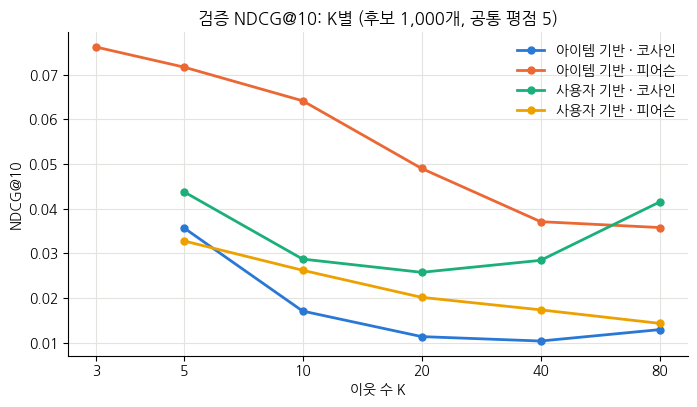

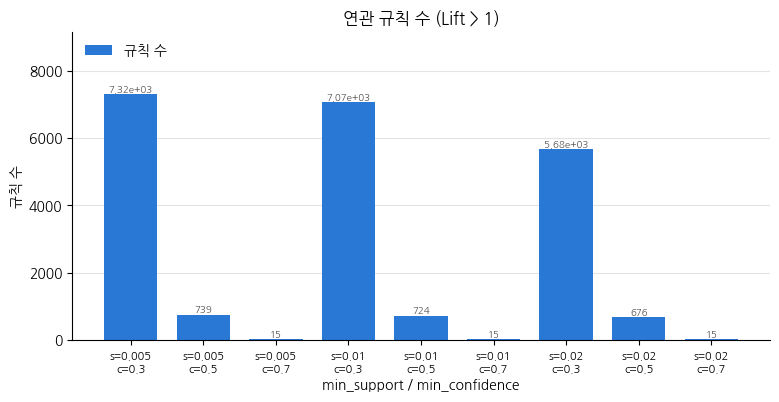

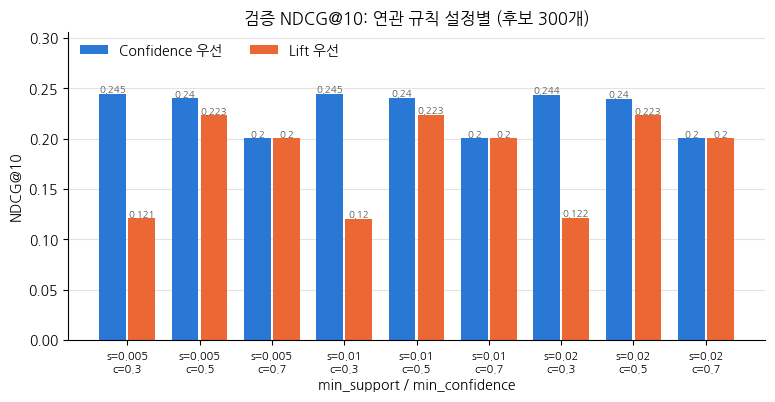

{
  "knn": {
    "kind": "item",
    "sim": "pearson",
    "K": 3,
    "min_common": 3,
    "ndcg_mean": 0.07772018447399175,
    "ndcg_std": 0.0013095539357643265,
    "rec_ms": 0.6008978559860743
  },
  "rules": {
    "min_support": 0.005,
    "min_conf": 0.3,
    "sort_by": "confidence",
    "ndcg_mean": 0.24199795046168582,
    "ndcg_std": 0.005250085782662317,
    "rec_ms": 1.186507976579082
  }
}


In [64]:
# 9-5. ▶ 실행: kNN·연관 규칙 파라미터 선택 (처음 10~20분, 이후 저장된 결과 재사용)
FORCE = False
if FORCE or not (RES / "selected.json").exists():
    tune_df, selected = tune()
else:
    print("저장된 설정을 재사용합니다 (outputs/results/selected.json). 다시 고르려면 FORCE = True")
    show_saved(["tune_knn_k.png", "tune_rules_count.png", "tune_rules_ndcg.png"])
print(json.dumps(json.load(open(RES / "selected.json", encoding="utf-8")), indent=2, ensure_ascii=False))

In [65]:
# 9-6. 🔍 파라미터 선택 과정 표: 전체 설정 점수(상위 10개)와 시드 3개 재평가
grid_df = pd.read_csv(RES / "tune_grid.csv")
cols = ["method", "kind", "sim", "K", "min_support", "min_conf", "sort_by", "cand", "ndcg", "precision", "recall", "fill_rate"]
print("kNN 상위 5개 (후보 1,000개)")
display(grid_df[grid_df["method"] == "knn"].nlargest(5, "ndcg")[cols].round(4))
print("연관 규칙 상위 5개 (후보 300개)")
display(grid_df[grid_df["method"] == "rules"].nlargest(5, "ndcg")[cols + ["n_rules", "rule_user_rate"]].round(4))
print("시드 42·7·101 재평가")
display(pd.read_csv(RES / "tune_reeval.csv").round(4))

kNN 상위 5개 (후보 1,000개)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,method,kind,sim,K,min_support,min_conf,sort_by,cand,ndcg,precision,recall,fill_rate
39,knn,item,pearson,3.0,NaN,NaN,NaN,c1000,0.0762,0.0579,0.0712,0.0
16,knn,item,pearson,5.0,NaN,NaN,NaN,c1000,0.0717,0.0552,0.0678,0.0
17,knn,item,pearson,10.0,NaN,NaN,NaN,c1000,0.0641,0.0492,0.0619,0.0
18,knn,item,pearson,20.0,NaN,NaN,NaN,c1000,0.0490,0.0389,0.0483,0.0
1,knn,user,cosine,5.0,NaN,NaN,NaN,c1000,0.0438,0.0380,0.0452,0.0


연관 규칙 상위 5개 (후보 300개)


,method,kind,sim,K,min_support,min_conf,sort_by,cand,ndcg,precision,recall,fill_rate,n_rules,rule_user_rate
27,rules,NaN,NaN,NaN,0.010,0.3,confidence,c300,0.2449,0.1498,0.2550,0.0005,7071.0,0.9995
21,rules,NaN,NaN,NaN,0.005,0.3,confidence,c300,0.2448,0.1499,0.2547,0.0005,7322.0,0.9995
33,rules,NaN,NaN,NaN,0.020,0.3,confidence,c300,0.2436,0.1488,0.2530,0.0010,5676.0,0.9995
29,rules,NaN,NaN,NaN,0.010,0.5,confidence,c300,0.2403,0.1449,0.2460,0.3433,724.0,0.9939
23,rules,NaN,NaN,NaN,0.005,0.5,confidence,c300,0.2401,0.1448,0.2455,0.3423,739.0,0.9939


시드 42·7·101 재평가


,kind,sim,K,min_common,ndcg_mean,ndcg_std,rec_ms,method,min_support,min_conf,sort_by
0,item,pearson,3.0,5.0,0.0776,0.0014,0.6243,knn,NaN,NaN,NaN
1,item,pearson,5.0,5.0,0.0735,0.0016,0.6560,knn,NaN,NaN,NaN
2,item,pearson,3.0,3.0,0.0777,0.0013,0.6009,knn,NaN,NaN,NaN
3,item,pearson,3.0,5.0,0.0776,0.0014,0.6089,knn,NaN,NaN,NaN
4,item,pearson,3.0,10.0,0.0771,0.0013,0.6512,knn,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,0.2420,0.0053,1.1865,rules,0.005,0.3,confidence
6,NaN,NaN,NaN,NaN,0.2416,0.0054,1.1765,rules,0.010,0.3,confidence


## 10. 🆕 선호 기준 7·8·9점 비교 (기획서 3.3 표 마지막 줄)
연관 규칙에서 "좋아함"으로 볼 점수를 7·8·9점으로 바꿔 본다. 바뀌는 곳은 **규칙 학습(트랜잭션)과 입력(내가 좋아한 게임)** 두 곳뿐이고,
**평가 정답 기준은 8점 그대로**다. 9장에서 고른 support·confidence·정렬 기준은 고정하고,
시드 42·7·101 세 분할의 평균 NDCG@10 으로 고른다(동점이면 빠른 쪽). 고른 값은 `like.json` 에 저장되어
이후 하이브리드·최종 테스트·추천에 쓰인다. 8점이 뽑히면 기존 결과와 같다.

In [66]:
# 10-1. 선호 기준 비교 함수
LIKE_LIST = [7.0, 8.0, 9.0]


def tune_like():
    """검증: 연관 규칙의 선호 기준을 7·8·9점으로 바꿔 비교 → like.json."""
    ctx = context()
    _, rule_cfg = selected_cfgs()
    rows = []
    # like는 규칙 학습과 추천 입력에만 넘긴다. 평가 정답을 만드는 전역 LIKE는 8점으로 유지해야 비교 기준이 같다.
    for like, s in tqdm(list(itertools.product(LIKE_LIST, SEEDS)), desc="선호 기준 3개 × 시드 3개"):
        row = run(ctx, get_split(ctx, "val", s), dict(rule_cfg, like=like), "c300")
        rows.append(dict(like=like, seed=s, **{k: row[k] for k in ["ndcg", "precision", "recall", "n_rules",
                                                                     "rule_user_rate", "fill_rate", "rec_ms"]}))
    df = pd.DataFrame(rows)
    df.to_csv(RES / "like_val_seeds.csv", index=False)
    g = df.groupby("like", as_index=False).agg(
        ndcg_mean=("ndcg", "mean"), ndcg_std=("ndcg", "std"), precision=("precision", "mean"),
        recall=("recall", "mean"), n_rules=("n_rules", "first"), rule_user_rate=("rule_user_rate", "mean"),
        fill_rate=("fill_rate", "mean"), rec_ms=("rec_ms", "mean"))
    g.to_csv(RES / "like_val.csv", index=False)
    best = g.sort_values(["ndcg_mean", "rec_ms"], ascending=[False, True]).iloc[0]
    json.dump({"like": float(best["like"]), "val_ndcg": float(best["ndcg_mean"])}, open(RES / "like.json", "w"),
              indent=2)
    bar_chart("tune_like.png", "검증: 연관 규칙 선호 기준별 (시드 3개 평균, 후보 300개)",
              [f"{l:g}점 이상" for l in g["like"]],
              {"NDCG@10": g["ndcg_mean"].tolist(), "Precision@10": g["precision"].tolist(),
               "Recall@10": g["recall"].tolist()}, ylabel="검증 사용자 평균")
    return g, float(best["like"])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


선호 기준 3개 × 시드 3개:   0%|          | 0/9 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

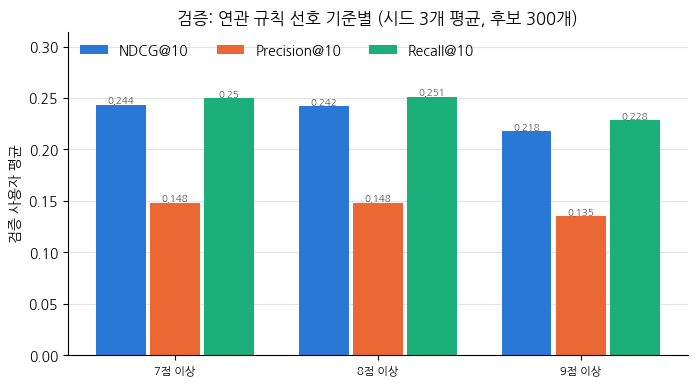

n_rules = 규칙 수, rule_user_rate = 규칙으로 추천받은 사용자 비율


,like,ndcg_mean,ndcg_std,precision,recall,n_rules,rule_user_rate,fill_rate,rec_ms
0,7.0,0.2437,0.0060,0.1484,0.2495,20202,1.0000,0.0000,1.8781
1,8.0,0.2420,0.0053,0.1481,0.2514,7322,0.9997,0.0003,1.1822
2,9.0,0.2179,0.0052,0.1350,0.2283,808,0.9506,0.4337,0.8390


선택된 선호 기준: 7.0 점 이상


In [67]:
# 10-2. ▶ 실행: 선호 기준 선택 (몇 분)
FORCE = False
if FORCE or not (RES / "like.json").exists():
    like_df, best_like = tune_like()
else:
    print("저장된 선호 기준을 재사용합니다 (outputs/results/like.json). 다시 고르려면 FORCE = True")
    show_saved(["tune_like.png"])
print("n_rules = 규칙 수, rule_user_rate = 규칙으로 추천받은 사용자 비율")
display(pd.read_csv(RES / "like_val.csv").round(4))
print("선택된 선호 기준:", json.load(open(RES / "like.json"))["like"], "점 이상")

## 11. 하이브리드 가중치 선택 (검증 데이터)
kNN 가중치 w 를 0.25 / 0.5 / 0.75 로 바꿔 비교한다(후보 300개). kNN·규칙 설정은 9·10장에서 고른 것.

In [68]:
# 11-1. 하이브리드 설정 읽기 함수
def hybrid_cfg():
    """selected.json + like.json + hybrid.json → 하이브리드 설정."""
    knn_cfg, rule_cfg = selected_cfgs()
    return dict(method="hybrid", w=json.load(open(RES / "hybrid.json"))["w"], knn=knn_cfg, rules=rule_cfg)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [69]:
# 11-2. 하이브리드 가중치 선택 함수
def tune_hybrid():
    """검증 데이터로 kNN 가중치 w (0.25 / 0.5 / 0.75) 선택 → hybrid.json."""
    ctx = context()
    knn_cfg, rule_cfg = selected_cfgs()
    split = get_split(ctx, "val", 42)
    rows = []
    # 앞서 선택한 kNN·규칙 설정과 검증 분할은 고정하고 혼합 비율만 비교한다. w가 클수록 kNN 점수 비중이 높다.
    for w in tqdm([0.25, 0.5, 0.75], desc="kNN 가중치 3개"):
        row = run(ctx, split, dict(method="hybrid", w=w, knn=knn_cfg, rules=rule_cfg), "c300")
        rows.append({k: row[k] for k in ["w", "ndcg", "precision", "recall", "fill_rate", "rec_ms"]})
    df = pd.DataFrame(rows)
    df.to_csv(RES / "hybrid_val.csv", index=False)
    best = df.sort_values(["ndcg", "rec_ms"], ascending=[False, True]).iloc[0]
    json.dump({"w": float(best["w"]), "val_ndcg": float(best["ndcg"])}, open(RES / "hybrid.json", "w"), indent=2)
    return df, float(best["w"])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [70]:
# 11-3. ▶ 실행: 하이브리드 가중치 선택 (1~2분)
FORCE = False
if FORCE or not (RES / "hybrid.json").exists():
    hybrid_df, best_w = tune_hybrid()
else:
    print("저장된 가중치를 재사용합니다 (outputs/results/hybrid.json). 다시 고르려면 FORCE = True")
display(pd.read_csv(RES / "hybrid_val.csv").round(4))
print("선택된 kNN 가중치 w:", json.load(open(RES / "hybrid.json"))["w"])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


kNN 가중치 3개:   0%|          | 0/3 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

,w,ndcg,precision,recall,fill_rate,rec_ms
0,0.25,0.2560,0.1547,0.2625,0.0,2.4936
1,0.50,0.2233,0.1347,0.2310,0.0,2.4666
2,0.75,0.1744,0.1071,0.1819,0.0,2.5425


선택된 kNN 가중치 w: 0.25


## 12. 🆕 행렬 분해 파라미터 선택 (검증 데이터)
잠재 차원 20·50·100 × 정규화 강도 0.001·0.01·0.1 = 9개 설정을 시드 42 분할로 평가(후보 1,000개) →
상위 2개를 시드 42·7·101 로 다시 평가해 평균 NDCG 최고(동점이면 빠른 쪽)를 고른다. kNN·연관 규칙과 같은 방식이다.

In [71]:
# 12-1. 행렬 분해 설정 읽기 함수
def mf_cfg():
    """mf.json → 행렬 분해 설정."""
    sel = json.load(open(RES / "mf.json"))
    return dict(method="mf", k=sel["k"], reg=sel["reg"])

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [72]:
# 12-2. 행렬 분해 파라미터 선택 함수
def tune_mf():
    """검증 데이터로 잠재 차원·정규화 강도 선택 → mf.json."""
    ctx = context()
    split = get_split(ctx, "val", 42)
    rows = []
    for k, reg in tqdm(list(itertools.product(MF_DIMS, MF_REGS)), desc="설정 9개 학습·평가"):
        cfg = dict(method="mf", k=k, reg=reg)
        t0 = time.time()
        m = mf_model(ctx, cfg)                                 # 학습 (이미 학습한 설정이면 재사용)
        # 동일 설정이 캐시에 있으면 실제 재학습 없이 조회한다. fit_s 비교 시 캐시 사용 여부와 최초 numba 컴파일 시간을 고려한다.
        fit_s = time.time() - t0
        row = run(ctx, split, cfg, "c1000")
        rows.append(dict(row, fit_s=fit_s, train_rmse=m["train_rmse"][-1]))
    df = pd.DataFrame(rows)
    df.to_csv(RES / "mf_grid.csv", index=False)

    # 상위 2개를 시드 3개로 재평가
    # 학습 RMSE가 아닌 검증 추천 순위로 설정을 고른다. 재평가 시드도 입력/정답 분할만 바꾸며 학습 모델은 재사용한다.
    top2 = df.nlargest(2, "ndcg")
    rr = [dict(run(ctx, get_split(ctx, "val", s), dict(method="mf", k=int(r["k"]), reg=float(r["reg"])), "c1000"),
               seed=s) for (_, r), s in tqdm(list(itertools.product(top2.iterrows(), SEEDS)), desc="상위 2개 시드 3개로 재평가")]
    g = pd.DataFrame(rr).groupby(["k", "reg"], as_index=False).agg(
        ndcg_mean=("ndcg", "mean"), ndcg_std=("ndcg", "std"), rec_ms=("rec_ms", "mean"))
    g.to_csv(RES / "mf_reeval.csv", index=False)
    best = g.sort_values(["ndcg_mean", "rec_ms"], ascending=[False, True]).iloc[0]
    sel = dict(k=int(best["k"]), reg=float(best["reg"]), epochs=MF_EPOCHS, lr=MF_LR,
               ndcg_mean=float(best["ndcg_mean"]), ndcg_std=float(best["ndcg_std"]))
    json.dump(sel, open(RES / "mf.json", "w"), indent=2)

    bar_chart("tune_mf_ndcg.png", "검증 NDCG@10: 행렬 분해 설정별 (후보 1,000개)", [f"차원 {k}" for k in MF_DIMS],
              {f"reg={reg}": [df[(df["k"] == k) & (df["reg"] == reg)]["ndcg"].iloc[0] for k in MF_DIMS]
               for reg in MF_REGS}, ylabel="NDCG@10")
    m = mf_model(ctx, mf_cfg())
    line_chart("tune_mf_rmse.png", f"선택된 행렬 분해(차원 {sel['k']}, reg {sel['reg']}) 학습 RMSE",
               {"학습 RMSE": (np.arange(1, MF_EPOCHS + 1), m["train_rmse"])}, "반복 횟수", "RMSE", log_base=None)
    return df, sel

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


설정 9개 학습·평가:   0%|          | 0/9 [00:00<?, ?it/s]

행렬 분해 학습 (차원 20, reg 0.001):   0%|          | 0/30 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

행렬 분해 학습 (차원 20, reg 0.1):   0%|          | 0/30 [00:00<?, ?it/s]

... (16 outputs left out)

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2000 [00:00<?, ?it/s]

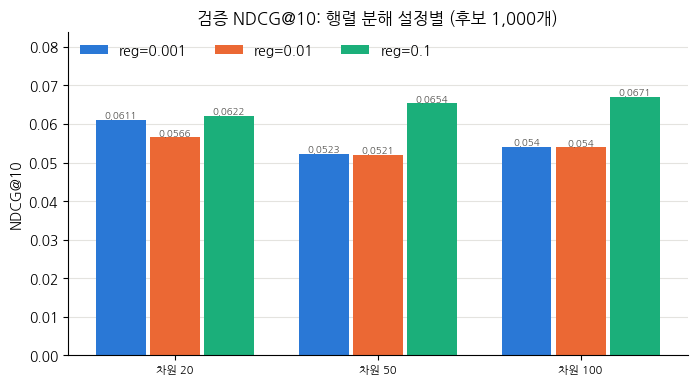

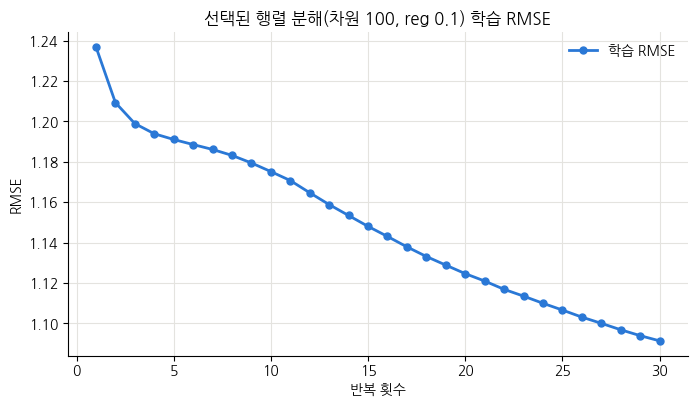

,k,reg,ndcg,precision,recall,train_rmse,fit_s,rec_ms
0,20,0.001,0.0611,0.0496,0.0538,0.9511,11.8374,0.6383
1,20,0.010,0.0566,0.0464,0.0486,0.9614,0.0000,0.6295
2,20,0.100,0.0622,0.0506,0.0566,1.1243,11.7385,0.6234
3,50,0.001,0.0523,0.0429,0.0435,0.7584,16.3881,0.7136
4,50,0.010,0.0521,0.0426,0.0447,0.7870,15.0793,0.6969
5,50,0.100,0.0654,0.0534,0.0595,1.1063,15.0893,0.7083
6,100,0.001,0.0540,0.0435,0.0481,0.5321,22.4672,1.2118
7,100,0.010,0.0540,0.0443,0.0489,0.5900,22.2476,1.0632
8,100,0.100,0.0671,0.0547,0.0607,1.0914,22.7360,1.2426


시드 42·7·101 재평가


,k,reg,ndcg_mean,ndcg_std,rec_ms
0,50,0.1,0.0668,0.0016,0.7121
1,100,0.1,0.0692,0.0019,1.2595


{'k': 100, 'reg': 0.1, 'epochs': 30, 'lr': 0.005, 'ndcg_mean': 0.0692146162502524, 'ndcg_std': 0.0018690406823359369}


In [73]:
# 12-3. ▶ 실행: 행렬 분해 파라미터 선택 (5~15분)
FORCE = False
if FORCE or not (RES / "mf.json").exists():
    mf_df, mf_sel = tune_mf()
else:
    print("저장된 설정을 재사용합니다 (outputs/results/mf.json). 다시 고르려면 FORCE = True")
    show_saved(["tune_mf_ndcg.png", "tune_mf_rmse.png"])
display(pd.read_csv(RES / "mf_grid.csv")[["k", "reg", "ndcg", "precision", "recall", "train_rmse", "fit_s", "rec_ms"]].round(4))
print("시드 42·7·101 재평가")
display(pd.read_csv(RES / "mf_reeval.csv").round(4))
print(json.load(open(RES / "mf.json")))

## 13. 최종 테스트
검증으로 고른 설정 그대로 테스트 사용자(2022년 새 사용자)에게 적용한다.
- **공정 비교**: 모든 방법을 같은 300개 후보·같은 사용자·같은 입력/정답 분할로 평가
- **1,000개 후보**: 인기 순·kNN·행렬 분해만 따로 (후보 수가 다른 점수는 한 표에서 우열 비교하지 않음)

공정 비교의 사용자별 점수는 `test_user_scores_c300.pkl` 로 저장해 14장 부트스트랩에 쓴다.

In [74]:
# 13-1. 최종 설정 모으기 함수
def final_cfgs():
    """검증으로 고른 기법별 설정."""
    knn_cfg, rule_cfg = selected_cfgs()
    return {"인기 순": dict(method="popular"), "kNN": knn_cfg, "연관 규칙": rule_cfg,
            "하이브리드": hybrid_cfg(), "행렬 분해": mf_cfg()}

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [75]:
# 13-2. 🔍 최종 테스트에 쓸 설정 확인
for name, cfg in final_cfgs().items():
    print(f"{name:6s}: {cfg}")

인기 순  : {'method': 'popular'}
kNN   : {'method': 'knn', 'kind': 'item', 'sim': 'pearson', 'K': 3, 'min_common': 3}
연관 규칙 : {'method': 'rules', 'min_support': 0.005, 'min_conf': 0.3, 'sort_by': 'confidence', 'like': 7.0}
하이브리드 : {'method': 'hybrid', 'w': 0.25, 'knn': {'method': 'knn', 'kind': 'item', 'sim': 'pearson', 'K': 3, 'min_common': 3}, 'rules': {'method': 'rules', 'min_support': 0.005, 'min_conf': 0.3, 'sort_by': 'confidence', 'like': 7.0}}
행렬 분해 : {'method': 'mf', 'k': 100, 'reg': 0.1}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [76]:
# 13-3. 최종 테스트 함수
def final_test():
    """테스트: 공정 비교(300개 후보)와 1,000개 후보 표·그래프, 사용자별 점수를 저장."""
    ctx = context()
    cfgs = final_cfgs()
    split = get_split(ctx, "test", 42)
    rows, scores = [], {}
    jobs = [(name, "c300") for name in cfgs] + [(name, "c1000") for name in ["인기 순", "kNN", "행렬 분해"]]
    bar = tqdm(jobs, desc="테스트 평가")
    for name, cand in bar:
        bar.set_postfix_str(f"{name} (후보 {cand[1:]}개)")
        row = run(ctx, split, cfgs[name], cand, keep_scores=(cand == "c300"))
        if cand == "c300":
            scores[name] = row.pop("scores")
        rows.append(dict(기법=name, **row))
    res = pd.DataFrame(rows)
    cols = ["기법", "ndcg", "precision", "recall", "n_eval", "n_excluded", "fill_rate", "rec_ms"]
    fair = res[res["cand"] == "c300"][cols + ["n_rules", "rule_user_rate"]].reset_index(drop=True)
    k1000 = res[res["cand"] == "c1000"][cols].reset_index(drop=True)
    fair.to_csv(RES / "test_fair300.csv", index=False, encoding="utf-8-sig")
    k1000.to_csv(RES / "test_c1000.csv", index=False, encoding="utf-8-sig")
    pd.to_pickle(scores, RES / "test_user_scores_c300.pkl")
    for df, name, title in [(fair, "test_fair300.png", "최종 테스트: 공정 비교 (후보 300개)"),
                            (k1000, "test_c1000.png", "최종 테스트: 후보 1,000개")]:
        bar_chart(name, title, ["NDCG@10", "Precision@10", "Recall@10"],
                  {r["기법"]: [r["ndcg"], r["precision"], r["recall"]] for _, r in df.iterrows()},
                  ylabel="테스트 사용자 평균", size=(9, 4.2))
    return fair, k1000

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [77]:
# 13-4. 추천 예시 함수
def recommendation_examples(ctx, split, cfgs):
    """테스트 사용자 2명의 좋아한 게임 → 기법별 추천 10개 (✔ = 정답 적중)."""
    g300 = set(ctx["g300"])
    ok = [(inp, t & g300) for inp, t in split if len(t & g300) >= 3]   # 300개 안에 정답 3개 이상인 사용자
    lines = []
    for i in sorted(np.random.default_rng(42).choice(len(ok), size=2, replace=False)):
        inp, truth = ok[i]
        lines += [f"### 사용자 {inp.name[0]}",
                  "- 좋아한 게임: " + ", ".join(names_of(inp[inp >= 8].sort_values().index[::-1][:6])),
                  "- 정답 게임: " + ", ".join(names_of(truth))]
        for name, cfg in cfgs.items():
            recs = make_rec(ctx, cfg, "c300")(inp, 10)
            lines.append(f"- **{name}** ({len(truth & set(recs))}개 적중): "
                         + ", ".join(("✔ " if g in truth else "") + str(NAMES.get(g, g)) for g in recs))
        lines.append("")
    text = "\n".join(lines)
    (RES / "test_examples.md").write_text(text, encoding="utf-8")
    return text

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


테스트 평가:   0%|          | 0/8 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2945 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2945 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2945 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2945 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2945 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2945 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2945 [00:00<?, ?it/s]

사용자별 추천·채점:   0%|          | 0/2945 [00:00<?, ?it/s]

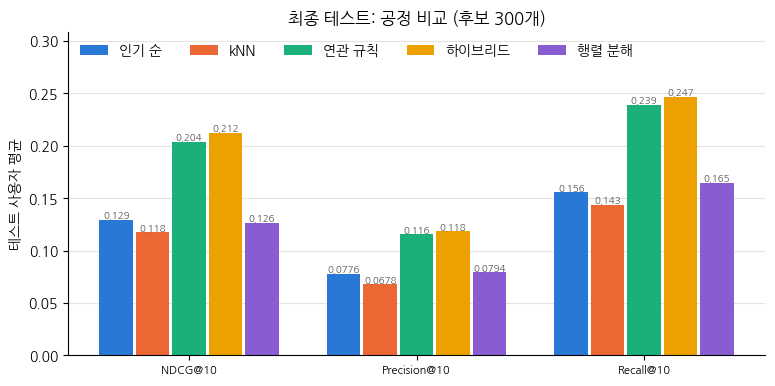

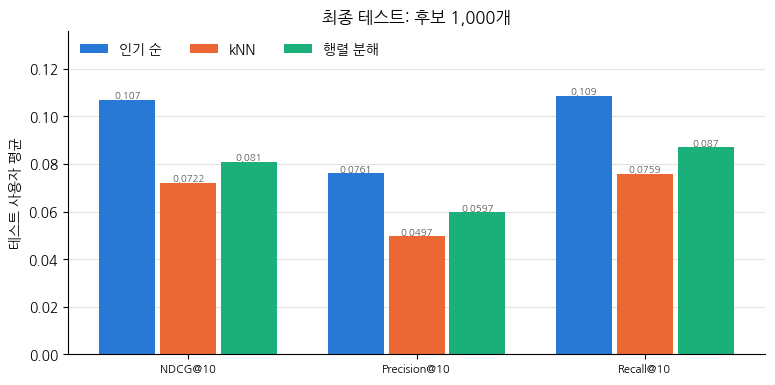

공정 비교 (후보 300개) — fill_rate = 인기 순으로 채운 칸 비율


,기법,ndcg,precision,recall,n_eval,n_excluded,fill_rate,rec_ms,n_rules,rule_user_rate
0,인기 순,0.1292,0.0776,0.1556,2850,95,0.0000,0.0585,NaN,NaN
1,kNN,0.1175,0.0678,0.1434,2850,95,0.0061,0.5739,NaN,NaN
2,연관 규칙,0.2038,0.1157,0.2390,2850,95,0.0000,1.8490,20202.0,1.0
3,하이브리드,0.2125,0.1182,0.2470,2850,95,0.0000,2.4908,NaN,NaN
4,행렬 분해,0.1264,0.0794,0.1648,2850,95,0.0000,1.0323,NaN,NaN


후보 1,000개


,기법,ndcg,precision,recall,n_eval,n_excluded,fill_rate,rec_ms
0,인기 순,0.1070,0.0761,0.1088,2907,38,0.0,0.0606
1,kNN,0.0722,0.0497,0.0759,2907,38,0.0,0.5902
2,행렬 분해,0.0810,0.0597,0.0870,2907,38,0.0,1.1941


In [78]:
# 13-5. ▶ 실행: 최종 테스트 (몇 분)
fair, k1000 = final_test()
print("공정 비교 (후보 300개) — fill_rate = 인기 순으로 채운 칸 비율")
display(fair.round(4))
print("후보 1,000개")
display(k1000.round(4))

In [79]:
# 13-6. 🔍 테스트 사용자 2명의 기법별 추천
display(Markdown(recommendation_examples(ctx, get_split(ctx, "test", 42), final_cfgs())))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### 사용자 Claytron33
- 좋아한 게임: Champions of Midgard, Kingdom Death: Monster, Guillotine, Carcassonne, Betrayal at House on the Hill, Munchkin
- 정답 게임: Ca$h 'n Guns (Second Edition), The 7th Continent, Everdell, Ticket to Ride, Raiders of the North Sea
- **인기 순** (1개 적중): Pandemic, Catan, Dominion, Codenames, ✔ Ticket to Ride, Puerto Rico, Agricola, Splendor, King of Tokyo, Love Letter
- **kNN** (0개 적중): Great Western Trail, Brass: Lancashire, Food Chain Magnate, Viticulture Essential Edition, Grand Austria Hotel, Robinson Crusoe: Adventures on the Cursed Island, Ora et Labora, The Quest for El Dorado, Chaos in the Old World, Bruges
- **연관 규칙** (1개 적중): Puerto Rico, Terraforming Mars, Azul, Pandemic, ✔ Ticket to Ride, Agricola, Power Grid, The Castles of Burgundy, Great Western Trail, 7 Wonders Duel
- **하이브리드** (1개 적중): Great Western Trail, ✔ Ticket to Ride, Puerto Rico, Terraforming Mars, Azul, Pandemic, Agricola, Wingspan, Power Grid, The Castles of Burgundy
- **행렬 분해** (0개 적중): Zombicide, Through the Ages: A New Story of Civilization, Terraforming Mars, Catan, Robinson Crusoe: Adventures on the Cursed Island, Gloomhaven, Caverna: The Cave Farmers, Arkham Horror, Eldritch Horror, Puerto Rico

### 사용자 jsmateusb
- 좋아한 게임: Root, Brass: Birmingham, Eldritch Horror, Dead of Winter: A Crossroads Game, Ticket to Ride, Coimbra
- 정답 게임: Five Tribes, Great Western Trail, Century: Spice Road, Cyclades, Raiders of the North Sea
- **인기 순** (0개 적중): Pandemic, 7 Wonders, Catan, Dominion, Small World, Puerto Rico, Agricola, King of Tokyo, Love Letter, Power Grid
- **kNN** (1개 적중): Brass: Lancashire, Ticket to Ride: Nordic Countries, Ticket to Ride: Europe, Arkham Horror, 7 Wonders, Azul, Concordia, ✔ Great Western Trail, Dixit, Descent: Journeys in the Dark (Second Edition)
- **연관 규칙** (1개 적중): Dixit, Azul, 7 Wonders, Pandemic, Puerto Rico, ✔ Great Western Trail, Power Grid, Concordia, Wingspan, Tzolk'in: The Mayan Calendar
- **하이브리드** (1개 적중): Azul, Dixit, 7 Wonders, ✔ Great Western Trail, Pandemic, Concordia, Puerto Rico, Brass: Lancashire, Power Grid, Ticket to Ride: Europe
- **행렬 분해** (1개 적중): Gloomhaven, Pandemic Legacy: Season 1, Star Wars: Rebellion, Twilight Struggle, Through the Ages: A New Story of Civilization, Gaia Project, Food Chain Magnate, Spirit Island, ✔ Great Western Trail, Brass: Lancashire


## 14. 🆕 부트스트랩 95% 신뢰구간 (기획서 3.4)
공정 비교에서 평가된 테스트 사용자를 **사용자 단위로 같은 인원수만큼 복원 추출**하는 과정을 1,000번 반복하고,
13장에서 저장한 사용자별 점수로 평균을 다시 구한다. 2.5·97.5 백분위수가 95% 신뢰구간이다.

- 방법 간 차이는 **매 반복에서 같은 사용자들**로 계산한다 (짝지은 비교).
- 차이의 신뢰구간이 0을 포함하지 않으면 `유의 = True`.
- 모델·설정값은 다시 학습·선택하지 않는다. 고정된 모델에서 **평가 사용자 구성이 달라질 때의 변동성**만 보여 주는 보조 자료다.

In [80]:
# 14-1. 부트스트랩 함수
METRICS = ["ndcg", "precision", "recall"]
PAIRS = [("연관 규칙", "인기 순"), ("연관 규칙", "kNN"), ("kNN", "인기 순"), ("하이브리드", "연관 규칙"),
         ("행렬 분해", "인기 순"), ("행렬 분해", "연관 규칙"), ("행렬 분해", "kNN")]


def bootstrap(scores, pairs, n_boot=1000, seed=SEED):
    """scores = {기법: 사용자별 (NDCG, Precision, Recall) 배열}. 기법별 성능과 기법 간 차이의 95% 신뢰구간 표."""
    n = len(next(iter(scores.values())))
    idx = np.random.default_rng(seed).integers(0, n, size=(n_boot, n))   # 모든 기법·차이에 같은 재표본 사용

    def ci(x):
        boot = x[idx].mean(axis=1)
        lo, hi = np.percentile(boot, [2.5, 97.5])
        return dict(평균=x.mean(), 하한=lo, 상한=hi)

    rows = []
    for name, s in scores.items():
        for j, met in enumerate(METRICS):
            rows.append(dict(구분="성능", 대상=name, 지표=met, **ci(s[:, j])))
    for a, b in pairs:
        for j, met in enumerate(METRICS):
            r = ci(scores[a][:, j] - scores[b][:, j])
            rows.append(dict(구분="차이", 대상=f"{a} - {b}", 지표=met, **r, 유의=(r["하한"] > 0) or (r["상한"] < 0)))
    table = pd.DataFrame(rows)
    table.to_csv(RES / "bootstrap.csv", index=False, encoding="utf-8-sig")
    return table

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [81]:
# 14-2. 신뢰구간 그래프 함수
def ci_chart(name, title, table, xlabel):
    """평균과 95% 신뢰구간 가로 오차 막대. 0 기준선 표시, 0 을 포함하는 구간은 회색."""
    fig, ax = plt.subplots(figsize=(8, 0.55 * len(table) + 1.2))
    y = np.arange(len(table))[::-1]
    for yi, (_, r) in zip(y, table.iterrows()):
        sig = bool(r.get("유의", True))
        ax.errorbar(r["평균"], yi, xerr=[[r["평균"] - r["하한"]], [r["상한"] - r["평균"]]], fmt="o", capsize=4,
                    color=COLORS[0] if sig else "#9b9a96")
        ax.text(r["상한"], yi + 0.18, f" {r['평균']:.3f} [{r['하한']:.3f}, {r['상한']:.3f}]", fontsize=8,
                color="#52514e")
    ax.axvline(0, color="#52514e", lw=1)
    ax.set_yticks(y, table["대상"])
    ax.set(title=title, xlabel=xlabel)
    ax.grid(axis="y", visible=False)
    save(fig, name)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


평가 사용자 2850명을 1,000번 복원 추출


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


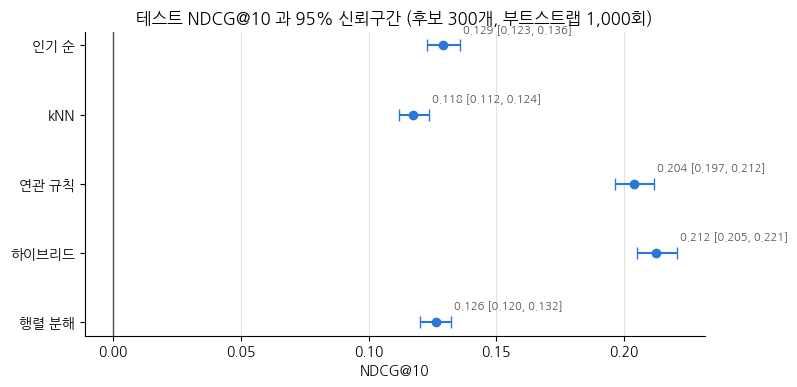

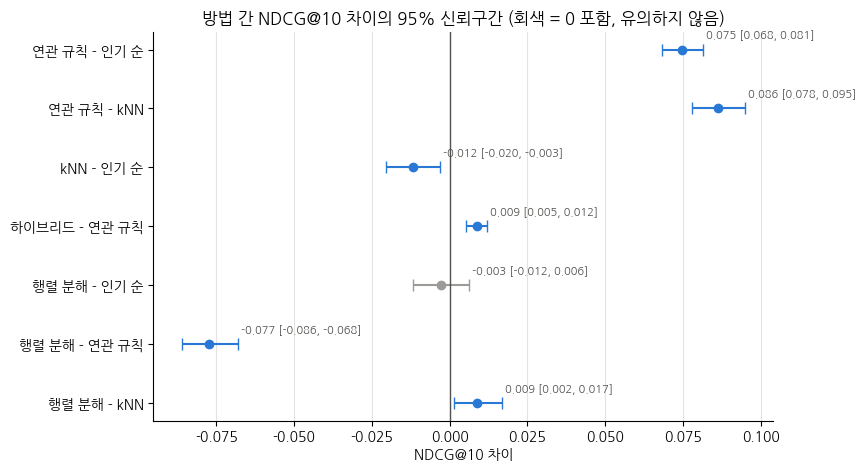

In [82]:
# 14-3. ▶ 실행: 부트스트랩 (수십 초)
scores = pd.read_pickle(RES / "test_user_scores_c300.pkl")
print(f"평가 사용자 {len(next(iter(scores.values())))}명을 1,000번 복원 추출")
bs = bootstrap(scores, PAIRS)
nd = bs[bs["지표"] == "ndcg"]
ci_chart("bootstrap_ndcg.png", "테스트 NDCG@10 과 95% 신뢰구간 (후보 300개, 부트스트랩 1,000회)",
         nd[nd["구분"] == "성능"], "NDCG@10")
ci_chart("bootstrap_diff_ndcg.png", "방법 간 NDCG@10 차이의 95% 신뢰구간 (회색 = 0 포함, 유의하지 않음)",
         nd[nd["구분"] == "차이"], "NDCG@10 차이")

In [83]:
# 14-4. 🔍 부트스트랩 전체 표 (NDCG·Precision·Recall)
display(bs.round(4))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,구분,대상,지표,평균,하한,상한,유의
0,성능,인기 순,ndcg,0.1292,0.1228,0.1358,NaN
1,성능,인기 순,precision,0.0776,0.0741,0.0814,NaN
2,성능,인기 순,recall,0.1556,0.1477,0.1628,NaN
3,성능,kNN,ndcg,0.1175,0.1118,0.1236,NaN
4,성능,kNN,precision,0.0678,0.0646,0.0710,NaN
5,성능,kNN,recall,0.1434,0.1366,0.1504,NaN
6,성능,연관 규칙,ndcg,0.2038,0.1965,0.2117,NaN
7,성능,연관 규칙,precision,0.1157,0.1114,0.1200,NaN
8,성능,연관 규칙,recall,0.2390,0.2298,0.2481,NaN
9,성능,하이브리드,ndcg,0.2125,0.2050,0.2205,NaN


In [84]:
# 14-5. ▶ 전체 결과 백업 (파일 탭에서 boardgame_rec_backup.zip 오른쪽 클릭 → 다운로드)
make_backup()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


백업 묶기:   0%|          | 0/42 [00:00<?, ?it/s]

/content/boardgame_rec_backup.zip (351MB) — 파일 탭에서 오른쪽 클릭 → 다운로드


## 15. 추천 시스템 직접 사용
내가 평가한 게임을 넣으면 기법별 추천 10개를 나란히 보여 준다. 추천 대상 1,000개에 없는 게임은 알려 주고 뺀다.
kNN(K가 작을 때)은 입력이 적으면 점수가 거의 안 나와서 예시는 12개를 넣는다.

In [85]:
# 15-1. 추천 함수
DEMO = {"Terraforming Mars": 10, "Agricola": 9, "Puerto Rico": 9, "Brass: Birmingham": 9,
        "Twilight Imperium: Fourth Edition": 9, "Gloomhaven": 8, "Scythe": 8, "Wingspan": 7,
        "Catan": 6, "Dixit": 5, "Munchkin": 4, "Monopoly": 2}


def recommend_for(my_ratings, method="전체", n=10):
    """{게임 이름 또는 BGG ID: 평점} → 추천 n개 표. method 에 "전체"를 주면 모든 기법을 나란히."""
    ctx = context()
    if "cfgs" not in ctx:                                      # 설정·이름 사전은 처음 한 번만
        ctx["cfgs"] = final_cfgs()
        ctx["ids"] = {str(NAMES.get(g, g)).lower(): g for g in ctx["g1000"]}   # 소문자 이름 → ID
        ctx["g1000_set"] = set(ctx["g1000"])
    mine = {}
    for key, r in my_ratings.items():
        g = key if key in ctx["g1000_set"] else ctx["ids"].get(str(key).strip().lower())
        if g is None:
            print(f"  '{key}' 은(는) 추천 대상 1,000개 게임에 없어 제외합니다.")
        else:
            mine[g] = float(r)
    inp = pd.Series(mine, dtype=float, name=("나", tuple(sorted(mine.items()))))   # name = 입력별 kNN 캐시 키
    table = {}
    for m in (list(ctx["cfgs"]) if method == "전체" else [method]):
        cfg = ctx["cfgs"][m]
        cand = "c1000" if cfg["method"] in ("knn", "popular", "mf") else "c300"
        table[m] = names_of(make_rec(ctx, cfg, cand)(inp, n))
    return pd.DataFrame(table, index=pd.RangeIndex(1, n + 1, name="순위"))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [86]:
# 15-2. 직접 입력 함수
def interactive():
    """'게임 이름, 평점'을 한 줄씩 입력 → 빈 줄이면 기법별 추천을 나란히 출력."""
    print("평가한 보드게임을 '이름, 평점' 형식으로 한 줄씩 입력하세요 (예: Catan, 9). 빈 줄이면 추천합니다.")
    mine = {}
    while line := input("> ").strip():
        name, _, r = line.rpartition(",")
        try:
            mine[name.strip()] = float(r)
        except ValueError:
            print("  형식: 게임 이름, 평점  (예: Catan, 9)")
    display(recommend_for(mine))

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [87]:
# 15-3. ▶ 예시 입력으로 추천
print("입력:", DEMO)
display(recommend_for(DEMO))

입력: {'Terraforming Mars': 10, 'Agricola': 9, 'Puerto Rico': 9, 'Brass: Birmingham': 9, 'Twilight Imperium: Fourth Edition': 9, 'Gloomhaven': 8, 'Scythe': 8, 'Wingspan': 7, 'Catan': 6, 'Dixit': 5, 'Munchkin': 4, 'Monopoly': 2}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,인기 순,kNN,연관 규칙,하이브리드,행렬 분해
순위,,,,,
1,Pandemic,Agricola (Revised Edition),7 Wonders,7 Wonders,Through the Ages: A New Story of Civilization
2,Carcassonne,Star Wars: Rebellion,Azul,Azul,Through the Ages: A Story of Civilization
3,7 Wonders,Brass: Lancashire,The Castles of Burgundy,The Castles of Burgundy,Gaia Project
4,Dominion,Twilight Imperium: Third Edition,Great Western Trail,Great Western Trail,On Mars
5,Codenames,Dixit: Journey,7 Wonders Duel,Brass: Lancashire,Great Western Trail
6,Ticket to Ride,Dixit: Odyssey,Power Grid,7 Wonders Duel,Terra Mystica
7,Small World,Munchkin Cthulhu,Pandemic,Power Grid,Twilight Struggle
8,Splendor,Pandemic,Dominion,Pandemic,Agricola (Revised Edition)
9,King of Tokyo,Carcassonne,Concordia,Dominion,Caverna: The Cave Farmers


In [88]:
# 15-4. ▶ 직접 입력해서 추천받기 (입력 칸이 뜨면 한 줄씩 입력, 빈 줄로 끝)
interactive()

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


평가한 보드게임을 '이름, 평점' 형식으로 한 줄씩 입력하세요 (예: Catan, 9). 빈 줄이면 추천합니다.
> Catan, 8
> Carcassonne, 7
> Ticket to Ride, 9
> Pandemic, 8
> Codenames, 9
> Azul, 8
> 7 Wonders, 6
> Dominion, 7
> Terraforming Mars, 10
> Wingspan, 9
> 


,인기 순,kNN,연관 규칙,하이브리드,행렬 분해
순위,,,,,
1,Small World,Ticket to Ride: Nordic Countries,7 Wonders Duel,7 Wonders Duel,Gloomhaven
2,Puerto Rico,Ticket to Ride: Europe,Scythe,Scythe,Kingdom Death: Monster
3,Agricola,Pandemic Legacy: Season 1,Puerto Rico,Puerto Rico,Pandemic Legacy: Season 1
4,Splendor,Codenames: Duet,Agricola,Ticket to Ride: Europe,Pandemic Legacy: Season 2
5,King of Tokyo,Codenames: Pictures,Splendor,Agricola,Brass: Birmingham
6,Love Letter,Dominion (Second Edition),The Castles of Burgundy,Splendor,Nemesis
7,Power Grid,Dominion: Intrigue,Patchwork,The Castles of Burgundy,Star Wars: Rebellion
8,The Castles of Burgundy,Small World,Power Grid,Patchwork,Tainted Grail: The Fall of Avalon
9,Dixit,Puerto Rico,Small World,Power Grid,Too Many Bones
